# RQ3 — Reading Behavior (Section 4.3)

> **RQ3: How does the presence of code smells influence developers' reading behavior when analyzing code snippets?**

The analysis is organized into three complementary perspectives. First, we test the aggregate
**Smell vs. Clean** comparison using participants' perception to define the condition. Second, we decompose
the results by perceived smell type (`LM`, `DC`, `FE`, `Others`, and `None`). Third, we perform complementary
**within-condition predominance analyses** for the paired reading dimensions.

The mental-model analysis follows the original four-state operationalization used by Abid et al.:
**Bottom-Up Inside, Top-Down Inside, Bottom-Up Outside, and Top-Down Outside**. The four states are defined
from fixation duration and are expressed as proportions of the total fixation time classified into those states.

| Analysis block | Inferential indicator | Tests | FDR family |
|---|---|---|---|
| Perceived smell presence | 4 mental-model state shares + $P_{TTB}$ + $P_{Thorough}$ + $P_{Sectionally}$ | 7 × `Smell vs. Clean` | one family of 7 |
| Predominance — Smell/Clean | overall $P_{BU}$, $P_{TTB}$, $P_{Thorough}$, $P_{Sectionally}$ | 4 × 2 conditions vs. 0.50 | one family of 8 |
| Predominance — perceived types | same 4 paired indicators | 4 × 5 categories vs. 0.50 | one family of 20 |
| A. Mental-model states | $P_{BU,I}$, $P_{TD,I}$, $P_{BU,O}$, $P_{TD,O}$ | 10 type-specific contrasts per state | four families of 10 |
| B. Reading direction | $P_{TTB}$ | 10 type-specific contrasts | one family of 10 |
| C. Reading depth | $P_{Thorough}$ | 10 type-specific contrasts | one family of 10 |
| D. Reading organization | $P_{Sectionally}$ | 10 type-specific contrasts | one family of 10 |

**Mental-model states.** For each `participant × snippet` cell, fixation duration is summed separately for
Bottom-Up Inside, Top-Down Inside, Bottom-Up Outside, and Top-Down Outside. Each state is divided by the
total duration across the four states, so the four proportions sum to 1. The marginal proportion of
Bottom-Up fixation time, $P_{BU}=P_{BU,I}+P_{BU,O}$, is retained only for the complementary Bottom-Up
versus Top-Down predominance analysis.

**Procedure used for between-condition contrasts:**

1. derive the reading-behavior indicators at the `participant × snippet` level;
2. aggregate snippets within each participant and condition/category;
3. retain only complete participant-level pairs;
4. compare paired values using **Yuen's paired test with 20% trimming**;
5. report the paired probability of superiority, $\hat p$, with a 95% percentile-bootstrap confidence interval;
6. control the false discovery rate using Benjamini--Hochberg within each predefined family.

For the predominance analysis, each paired-dimension proportion is compared with 0.50 using a two-sided
one-sample test for a 20% trimmed mean with Winsorized variance. We also report $\hat p_{pred}$, the
proportion of participants whose value lies above 0.50, with ties contributing 0.5.

**Terminology.** The Bottom-Up/Top-Down labels are gaze-based operational indicators derived from the
framework adopted by the study; they are not direct measurements of an internal cognitive process.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import t as student_t

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ------------------------------------------------------------
# Statistical parameters
# ------------------------------------------------------------

ALPHA = 0.05
TRIM = 0.20
N_BOOT = 10_000
SEED = 20260101


# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd()

PROJECT_ROOT = NOTEBOOK_DIR.parent

ANALYSIS_DIR = PROJECT_ROOT / "analysis"

BASE_PATH = (
    PROJECT_ROOT
    / "data"
    / "base_fixations_design_survey.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "rq3"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Import shared analysis modules
# ------------------------------------------------------------

if str(ANALYSIS_DIR) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_DIR))

from robust_stats import (
    benjamini_hochberg,
    paired_phat,
    paired_phat_bootstrap_ci,
    yuen_paired,
)

from utils import (
    build_group_pairs,
    descriptive_by_group,
    participant_group_summary,
)


# ------------------------------------------------------------
# Validate paths
# ------------------------------------------------------------

if not BASE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {BASE_PATH.resolve()}"
    )

print("Project root :", PROJECT_ROOT.resolve())
print("Dataset      :", BASE_PATH.resolve())
print("Analysis dir :", ANALYSIS_DIR.resolve())
print("Output dir   :", OUTPUT_DIR.resolve())

Project root : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update
Dataset      : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/data/base_fixations_design_survey.csv
Analysis dir : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/analysis
Output dir   : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq3


### Helper functions

`compare_paired` is used across the inferential blocks. It receives the complete participant-level pairs
for one contrast and returns the Yuen test, paired probability of superiority, and bootstrap confidence
interval in one result record. Because all RQ3 metrics are proportions, between-condition differences are
also reported in **percentage points** (`_pp`).

In [2]:
MIN_PAIRS = 3


def compare_paired(pairs: pd.DataFrame, comparison: str) -> dict:
    # Paired Yuen test and paired probability of superiority for an A-vs.-B contrast.
    group_a = pairs["value_a"]
    group_b = pairs["value_b"]

    yuen = yuen_paired(group_a, group_b, trim=TRIM, alpha=ALPHA, percent_points=True)
    phat = paired_phat(group_a, group_b)
    boot = paired_phat_bootstrap_ci(
        group_a,
        group_b,
        n_boot=N_BOOT,
        alpha=ALPHA,
        seed=SEED,
    )

    return {
        "comparison": comparison,
        "n": yuen["n"],
        "mean_a": float(group_a.mean()),
        "mean_b": float(group_b.mean()),
        "delta": yuen["trimmed_mean_diff"],
        "delta_pp": yuen["trimmed_mean_diff_pp"],
        "ci_low_pp": yuen["ci_low_pp"],
        "ci_high_pp": yuen["ci_high_pp"],
        "t": yuen["t"],
        "df": yuen["df"],
        "p_value": yuen["p_value"],
        "phat": phat["phat"],
        "phat_ci_low": boot["phat_ci_low"],
        "phat_ci_high": boot["phat_ci_high"],
        "n_a_gt_b": phat["n_x_gt_y"],
        "n_a_lt_b": phat["n_x_lt_y"],
    }


def participant_pairs(
    data: pd.DataFrame,
    group_col: str,
    metric_col: str,
    group_a: str,
    group_b: str,
) -> pd.DataFrame:
    # Mean metric value per participant and group, retaining complete pairs only.
    participant_table = participant_group_summary(
        data,
        group_col=group_col,
        metric_col=metric_col,
    )

    return build_group_pairs(
        participant_table,
        group_col=group_col,
        group_a=group_a,
        group_b=group_b,
    )


def median_iqr(values: pd.Series, decimals: int = 2) -> str:
    return (
        f"{values.median():,.{decimals}f} "
        f"[{values.quantile(0.25):,.{decimals}f}, "
        f"{values.quantile(0.75):,.{decimals}f}]"
    )


def format_interval(low: float, high: float, decimals: int = 2) -> str:
    return f"[{low:,.{decimals}f}, {high:,.{decimals}f}]"


def format_results_table(results: pd.DataFrame, with_indicator: bool = False) -> pd.DataFrame:
    # Format Yuen + p-hat results for manuscript-style presentation.
    columns = {
        "Comparison": results["comparison"],
        "n": results["n"],
        "Δ (p.p.)": results["delta_pp"].map(lambda v: f"{v:,.2f}"),
        "95% CI Δ": [
            format_interval(row["ci_low_pp"], row["ci_high_pp"])
            for _, row in results.iterrows()
        ],
        "p": results["p_value"].map(lambda v: f"{v:.4f}"),
        "p_FDR": results["p_fdr"].map(lambda v: f"{v:.4f}"),
        "p-hat": results["phat"].map(lambda v: f"{v:.2f}"),
        "95% CI p-hat": [
            format_interval(row["phat_ci_low"], row["phat_ci_high"])
            for _, row in results.iterrows()
        ],
    }

    if with_indicator:
        columns = {"Indicator": results["indicator"], **columns}

    return pd.DataFrame(columns)


def run_smell_vs_clean(indicators: dict) -> pd.DataFrame:
    # Compare Smell vs. Clean across indicators and adjust p-values within one family.
    rows = []

    for indicator, column in indicators.items():
        pairs = participant_pairs(
            snippet_metrics,
            group_col="perceived_group",
            metric_col=column,
            group_a="Smell",
            group_b="Clean",
        )

        if len(pairs) < MIN_PAIRS:
            rows.append(
                {
                    "family": "Smell vs. Clean",
                    "indicator": indicator,
                    "metric": column,
                    "comparison": "Smell vs. Clean",
                    "n": len(pairs),
                    "status": "insufficient pairs",
                }
            )
            continue

        rows.append(
            {
                "family": "Smell vs. Clean",
                "indicator": indicator,
                "metric": column,
                **compare_paired(pairs, "Smell vs. Clean"),
                "status": "ok",
            }
        )

    results = pd.DataFrame(rows)

    results["p_fdr"] = np.nan
    valid = results["status"].eq("ok")
    results.loc[valid, "p_fdr"] = benjamini_hochberg(
        results.loc[valid, "p_value"]
    )

    return results


def describe_smell_clean(indicators: dict) -> pd.DataFrame:
    # Participant-level median [IQR] for Smell and Clean.
    rows = []

    for indicator, column in indicators.items():
        participant_table = participant_group_summary(
            snippet_metrics.dropna(subset=["perceived_group"]),
            group_col="perceived_group",
            metric_col=column,
        )

        summary = descriptive_by_group(
            participant_table,
            group_col="perceived_group",
        )

        for _, row in summary.iterrows():
            rows.append(
                {
                    "Indicator": indicator,
                    "Group": row["perceived_group"],
                    "Participants": int(row["n_participants"]),
                    "Median [IQR]": (
                        f"{row['median']:.3f} "
                        f"[{row['q1']:.3f}, {row['q3']:.3f}]"
                    ),
                }
            )

    result = pd.DataFrame(rows)

    return result.pivot(
        index="Indicator",
        columns="Group",
        values="Median [IQR]",
    )[["Smell", "Clean"]]

# ------------------------------------------------------------
# Predominance analyses within each condition
# ------------------------------------------------------------

REFERENCE_PROPORTION = 0.50

PATTERN_DIRECTIONS = {
    "P(Bottom-Up overall)": ("Bottom-Up", "Top-Down"),
    "P(Top-to-Bottom)": ("Top-to-Bottom", "Bottom-to-Top"),
    "P(Thorough) @ 1000 ms": ("Thorough", "Skimming"),
    "P(Sectionally) @ three-line moving window": ("Sectionally", "Disorderly"),
}


def trimmed_mean_one_sample(
    values,
    reference: float = REFERENCE_PROPORTION,
    trim: float = TRIM,
    alpha: float = ALPHA,
) -> dict:
    """
    Two-sided one-sample test for a trimmed mean.

    Uncertainty in the trimmed mean is estimated using Winsorized variance.
    H0: trimmed_mean == reference.
    """

    x = pd.Series(values).dropna().astype(float).to_numpy()
    x = x[np.isfinite(x)]

    n = len(x)
    g = int(np.floor(trim * n))
    h = n - 2 * g

    if h < 2:
        raise ValueError(
            f"Insufficient sample for trimming={trim}: n={n}, h={h}."
        )

    ordered = np.sort(x)
    trimmed = ordered[g : n - g] if g > 0 else ordered
    trimmed_mean = float(trimmed.mean())

    winsorized = ordered.copy()

    if g > 0:
        winsorized[:g] = ordered[g]
        winsorized[n - g :] = ordered[n - g - 1]

    winsorized_variance = float(np.var(winsorized, ddof=1))

    # Estimated variance of the trimmed mean.
    se = float(
        np.sqrt(
            (n - 1)
            * winsorized_variance
            / (h * (h - 1))
        )
    )

    df = h - 1
    delta = trimmed_mean - reference

    if np.isclose(se, 0.0):
        if np.isclose(delta, 0.0):
            t_value = 0.0
            p_value = 1.0
        else:
            t_value = float(np.sign(delta) * np.inf)
            p_value = 0.0
    else:
        t_value = float(delta / se)
        p_value = float(
            2 * student_t.sf(abs(t_value), df)
        )

    critical = float(
        student_t.ppf(1 - alpha / 2, df)
    )

    ci_low = float(trimmed_mean - critical * se)
    ci_high = float(trimmed_mean + critical * se)

    return {
        "n": n,
        "trimmed_mean": trimmed_mean,
        "delta": delta,
        "delta_pp": 100 * delta,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "ci_low_pp": 100 * (ci_low - reference),
        "ci_high_pp": 100 * (ci_high - reference),
        "se": se,
        "t": t_value,
        "df": df,
        "p_value": p_value,
    }


def predominance_probability(
    values,
    reference: float = REFERENCE_PROPORTION,
    n_boot: int = N_BOOT,
    alpha: float = ALPHA,
    seed: int = SEED,
) -> dict:
    """
    p_pred = proportion of participants above `reference`.
    Ties contribute 0.5. The CI is a participant-level percentile bootstrap interval.
    """

    x = pd.Series(values).dropna().astype(float).to_numpy()
    x = x[np.isfinite(x)]

    if len(x) == 0:
        raise ValueError("No valid observations.")

    scores = np.where(
        x > reference,
        1.0,
        np.where(x < reference, 0.0, 0.5),
    )

    p_pred = float(scores.mean())

    rng = np.random.default_rng(seed)
    indices = rng.integers(
        0,
        len(scores),
        size=(n_boot, len(scores)),
    )
    boot = scores[indices].mean(axis=1)

    return {
        "p_pred": p_pred,
        "p_pred_ci_low": float(np.quantile(boot, alpha / 2)),
        "p_pred_ci_high": float(np.quantile(boot, 1 - alpha / 2)),
        "n_above": int((x > reference).sum()),
        "n_below": int((x < reference).sum()),
        "n_equal": int((x == reference).sum()),
    }


def participant_values_for_group(
    data: pd.DataFrame,
    group_col: str,
    metric_col: str,
) -> pd.DataFrame:
    """
    One value per participant × group, using the same mean aggregation
    used in the notebook's paired contrasts.
    """

    return (
        data[
            ["participant_id", group_col, metric_col]
        ]
        .dropna(
            subset=["participant_id", group_col, metric_col]
        )
        .groupby(
            ["participant_id", group_col],
            as_index=False,
        )[metric_col]
        .mean()
    )


def run_predominance(
    data: pd.DataFrame,
    group_col: str,
    groups: list,
    indicators: dict,
    family: str,
    reference: float = REFERENCE_PROPORTION,
) -> pd.DataFrame:
    """
    For each indicator × group:
    - aggregate snippets within participant × group;
    - test the trimmed mean against 0.50;
    - compute p_pred and its bootstrap CI;
    - apply BH-FDR to the complete specified family.
    """

    rows = []
    test_index = 0

    for indicator, metric_col in indicators.items():
        participant_table = participant_values_for_group(
            data,
            group_col=group_col,
            metric_col=metric_col,
        )

        above_label, below_label = PATTERN_DIRECTIONS[indicator]

        for group in groups:
            values = participant_table.loc[
                participant_table[group_col].eq(group),
                metric_col,
            ].dropna()

            if len(values) < MIN_PAIRS:
                rows.append(
                    {
                        "family": family,
                        "indicator": indicator,
                        "metric": metric_col,
                        "condition": group,
                        "comparison": f"{group} vs. {reference:.2f}",
                        "n": len(values),
                        "status": "insufficient participants",
                        "pattern_if_above": above_label,
                        "pattern_if_below": below_label,
                    }
                )
                continue

            test = trimmed_mean_one_sample(
                values,
                reference=reference,
            )

            pred = predominance_probability(
                values,
                reference=reference,
                seed=SEED + test_index,
            )
            test_index += 1

            rows.append(
                {
                    "family": family,
                    "indicator": indicator,
                    "metric": metric_col,
                    "condition": group,
                    "comparison": f"{group} vs. {reference:.2f}",
                    "reference": reference,
                    **test,
                    **pred,
                    "pattern_if_above": above_label,
                    "pattern_if_below": below_label,
                    "status": "ok",
                }
            )

    results = pd.DataFrame(rows)

    results["p_fdr"] = np.nan
    valid = results["status"].eq("ok")

    results.loc[valid, "p_fdr"] = benjamini_hochberg(
        results.loc[valid, "p_value"]
    )

    def conclusion(row):
        if row["status"] != "ok":
            return "Not tested"

        if not row["p_fdr"] < ALPHA:
            return "No clear predominance"

        if row["delta"] > 0:
            return row["pattern_if_above"]

        if row["delta"] < 0:
            return row["pattern_if_below"]

        return "No clear predominance"

    results["predominance"] = results.apply(
        conclusion,
        axis=1,
    )

    return results


def format_predominance_table(
    results: pd.DataFrame,
) -> pd.DataFrame:
    """Format predominance-test results for inspection and export."""

    valid = results.loc[
        results["status"].eq("ok")
    ].copy()

    return pd.DataFrame(
        {
            "Indicator": valid["indicator"],
            "Condition": valid["condition"],
            "n": valid["n"],
            "Trimmed mean": valid["trimmed_mean"].map(
                lambda v: f"{v:.3f}"
            ),
            "Δ vs. 0.50 (p.p.)": valid["delta_pp"].map(
                lambda v: f"{v:,.2f}"
            ),
            "95% CI Δ": [
                format_interval(
                    row["ci_low_pp"],
                    row["ci_high_pp"],
                )
                for _, row in valid.iterrows()
            ],
            "p": valid["p_value"].map(
                lambda v: f"{v:.4f}"
            ),
            "p_FDR": valid["p_fdr"].map(
                lambda v: f"{v:.4f}"
            ),
            "p_pred": valid["p_pred"].map(
                lambda v: f"{v:.2f}"
            ),
            "95% CI p_pred": [
                format_interval(
                    row["p_pred_ci_low"],
                    row["p_pred_ci_high"],
                )
                for _, row in valid.iterrows()
            ],
            "n > 0.50": valid["n_above"],
            "n < 0.50": valid["n_below"],
            "n = 0.50": valid["n_equal"],
            "Predominance": valid["predominance"],
        }
    )

## 1. Fixation dataset

In [3]:
from fixation_filter import MAX_FIXATION_MS, exclude_long_fixations

fixations = pd.read_csv(BASE_PATH)
# Exclude implausibly long fixations (> MAX_FIXATION_MS); see analysis/fixation_filter.py
fixations = exclude_long_fixations(fixations, max_ms=MAX_FIXATION_MS)


KEY = ["participant_id", "snippet_id"]

# Temporal order defines transitions between consecutive fixations.
fixations = fixations.sort_values(
    KEY + ["fixation_run_id", "fixation_start_event_time"]
).reset_index(drop=True)

print(f"Fixations                     : {len(fixations):,}")
print(f"Participants                  : {fixations['participant_id'].nunique()}")
print(f"Snippets                      : {fixations['snippet_id'].nunique()}")
print(
    "Participant × snippet cells   :",
    fixations[KEY].drop_duplicates().shape[0],
)
print(
    "Cells with more than one run  :",
    int(fixations.groupby(KEY)["fixation_run_id"].nunique().gt(1).sum()),
)

Excluded fixations > 5,000 ms: 528 of 74,412 (0.71% of fixations, 15.19% of fixation time); re-classified successors: 489
Fixations                     : 73,884
Participants                  : 25
Snippets                      : 12
Participant × snippet cells   : 297
Cells with more than one run  : 3


---
## 2. Metrics at the participant × snippet level

All RQ3 indicators are proportions computed within each `participant × snippet` cell. Survey variables and
MLCQ design variables are constant within the cell and are therefore carried forward during aggregation.

### 2.1 Mental-model states — Bottom-Up/Top-Down × Inside/Outside

Following Abid et al., the mental-model analysis combines two dimensions already represented in the
fixation-level dataset:

- **Bottom-Up vs. Top-Down**, taken from the `event` column;
- **Inside vs. Outside**, taken from the `inside` column, which indicates whether the fixation occurred
  within the target snippet.

This produces four mutually exclusive gaze states for each fixation:

1. Bottom-Up Inside;
2. Top-Down Inside;
3. Bottom-Up Outside;
4. Top-Down Outside.

For each `participant × snippet` cell, we sum fixation duration within each state:

\[
T_{BU,I},\quad T_{TD,I},\quad T_{BU,O},\quad T_{TD,O}.
\]

The total classified fixation time is

\[
T =
T_{BU,I}+T_{TD,I}+T_{BU,O}+T_{TD,O}.
\]

The four mental-model state proportions are therefore

\[
P_{BU,I}=\frac{T_{BU,I}}{T},\qquad
P_{TD,I}=\frac{T_{TD,I}}{T},
\]

\[
P_{BU,O}=\frac{T_{BU,O}}{T},\qquad
P_{TD,O}=\frac{T_{TD,O}}{T}.
\]

By construction,

\[
P_{BU,I}+P_{TD,I}+P_{BU,O}+P_{TD,O}=1.
\]

For descriptive and predominance purposes, we also derive the marginal proportions

\[
P_{BU}=P_{BU,I}+P_{BU,O},
\qquad
P_{TD}=P_{TD,I}+P_{TD,O},
\]

and

\[
P_{Outside}=P_{BU,O}+P_{TD,O},
\qquad
P_{Inside}=1-P_{Outside}.
\]

The four state shares are used for the between-condition mental-model comparisons. The overall
$P_{BU}$ is used only for the complementary Bottom-Up versus Top-Down predominance analysis.

In [4]:
MENTAL_TIME_COLUMNS = [
    "t_bu_in",
    "t_td_in",
    "t_bu_out",
    "t_td_out",
]

DESIGN_COLUMNS = [
    "smell_mlcq",
    "severity_mlcq",
    "perceived_smell_yn",
    "perceived_lm",
    "perceived_dc",
    "perceived_fe",
    "perceived_other",
]

inconsistent = [
    column
    for column in DESIGN_COLUMNS
    if fixations.groupby(KEY)[column].nunique(dropna=False).gt(1).any()
]

if inconsistent:
    raise ValueError(
        f"Columns with more than one value within a participant × snippet cell: {inconsistent}"
    )

duration = pd.to_numeric(fixations["duration"], errors="coerce")

if duration.isna().any():
    raise ValueError(
        f"There are {int(duration.isna().sum())} fixations with missing/non-numeric duration."
    )

if duration.lt(0).any():
    raise ValueError(
        f"There are {int(duration.lt(0).sum())} fixations with negative duration."
    )

inside = fixations["inside"]

if not (
    inside.dropna().isin([True, False]).all()
    or inside.dropna().isin([0, 1]).all()
):
    raise ValueError(
        "The `inside` column must contain Boolean or binary values."
    )

inside = inside.astype(bool)

flags = pd.DataFrame(
    {
        "bu_in": fixations["event"].eq("bottom-up") & inside,
        "td_in": fixations["event"].eq("top-down") & inside,
        "bu_out": fixations["event"].eq("bottom-up") & ~inside,
        "td_out": fixations["event"].eq("top-down") & ~inside,
    },
    index=fixations.index,
)

mental_time_rows = pd.DataFrame(
    {
        "t_bu_in": duration.where(flags["bu_in"], 0.0),
        "t_td_in": duration.where(flags["td_in"], 0.0),
        "t_bu_out": duration.where(flags["bu_out"], 0.0),
        "t_td_out": duration.where(flags["td_out"], 0.0),
    },
    index=fixations.index,
)

mental_time = (
    pd.concat([fixations[KEY], mental_time_rows], axis=1)
    .groupby(KEY, as_index=True)
    .sum()
)

design = fixations.groupby(KEY)[DESIGN_COLUMNS].first()

snippet_metrics = mental_time.join(design)

mental_total_time = snippet_metrics[MENTAL_TIME_COLUMNS].sum(axis=1)


def proportion(
    numerator: pd.Series,
    denominator: pd.Series,
) -> pd.Series:
    """Return a proportion only where the denominator is positive."""

    return numerator.where(denominator > 0).div(
        denominator.where(denominator > 0)
    )


MENTAL_STATE_COLUMNS = {
    "p_bu_inside": "t_bu_in",
    "p_td_inside": "t_td_in",
    "p_bu_outside": "t_bu_out",
    "p_td_outside": "t_td_out",
}

for proportion_name, time_name in MENTAL_STATE_COLUMNS.items():
    snippet_metrics[proportion_name] = proportion(
        snippet_metrics[time_name],
        mental_total_time,
    )

# Marginal proportions derived from the four-state composition.
snippet_metrics["p_bottom_up"] = (
    snippet_metrics["p_bu_inside"]
    + snippet_metrics["p_bu_outside"]
)

snippet_metrics["p_top_down"] = (
    snippet_metrics["p_td_inside"]
    + snippet_metrics["p_td_outside"]
)

snippet_metrics["p_outside"] = (
    snippet_metrics["p_bu_outside"]
    + snippet_metrics["p_td_outside"]
)

snippet_metrics["p_inside"] = (
    snippet_metrics["p_bu_inside"]
    + snippet_metrics["p_td_inside"]
)

state_sum = snippet_metrics[
    [
        "p_bu_inside",
        "p_td_inside",
        "p_bu_outside",
        "p_td_outside",
    ]
].sum(axis=1)

valid_state_sum = mental_total_time.gt(0)

if not np.allclose(
    state_sum.loc[valid_state_sum],
    1.0,
    rtol=1e-10,
    atol=1e-10,
):
    raise ValueError(
        "The four mental-model state proportions do not sum to 1."
    )

print(
    "Cells with no classified Bottom-Up/Top-Down fixation time:",
    int(mental_total_time.eq(0).sum()),
)

print(
    "Total classified mental-model fixation time (ms):",
    f"{mental_total_time.sum():,.2f}",
)

display(
    snippet_metrics[
        [
            "t_bu_in",
            "t_td_in",
            "t_bu_out",
            "t_td_out",
            "p_bu_inside",
            "p_td_inside",
            "p_bu_outside",
            "p_td_outside",
            "p_bottom_up",
            "p_outside",
        ]
    ].head()
)

Cells with no classified Bottom-Up/Top-Down fixation time: 0
Total classified mental-model fixation time (ms): 34,712,068.00


t_bu_in  t_td_in  t_bu_out  t_td_out  p_bu_inside  p_td_inside  p_bu_outside  p_td_outside  p_bottom_up  p_outside
participant_id snippet_id                                                                                                                    
1              2             11865    14545       227       228     0.441653     0.541411       0.00845      0.008487     0.450102   0.016937
               3               410    11641         0         0     0.034022     0.965978       0.00000      0.000000     0.034022   0.000000
               4              6407     2734         0         0     0.700908     0.299092       0.00000      0.000000     0.700908   0.000000
               5              5930     6494         0         0     0.477302     0.522698       0.00000      0.000000     0.477302   0.000000
               6              3430     6835       149       470     0.315141     0.627986       0.01369      0.043183     0.328831   0.056872

### 2.2 Reading direction, depth, and organization

**Direction.** For each pair of consecutive fixations within the same `fixation_run_id`, we compare source-code
line numbers. A transition is Top-to-Bottom when the next fixation is on a lower line and Bottom-to-Top when
it is on a higher line. Same-line transitions are excluded from the directional denominator:

$$P_{TTB} =
\frac{N_{TopToBottom}}
{N_{TopToBottom}+N_{BottomToTop}}.$$

**Depth.** Reading depth is operationalized as the proportion of fixations classified as Thorough, retaining
the original 1000-ms threshold:

$$P_{Thorough} =
\frac{N_{fixations > 1000\,ms}}
{N_{valid\ fixations}}.$$

Thresholds of 300, 500, and 750 ms are computed only for sensitivity analysis.

**Organization.** Reading organization is operationalized with a **three-line moving window centered on the
currently fixated line**. For two consecutive fixations, the transition is classified as Sectionally when the
next fixation remains on the current line or on one of its immediately adjacent lines:

$$|\Delta line| \le 1.$$

For example, if the current fixation is on line 4, lines 3, 4, and 5 form the local three-line window for
that transition. A transition outside this window is classified as Disorderly.

The primary indicator is:

$$P_{Sectionally} =
\frac{N_{|\Delta line|\le1}}
{N_{valid\ transitions}}.$$

The previous fixed three-line-block definition and the alternative windows
$|\Delta line|\le2,3,5$ are retained only as sensitivity analyses.

In [5]:
SECTION_SIZE = 3
THOROUGH_THRESHOLDS = [300, 500, 750, 1000]
SECTION_WINDOWS = [1, 2, 3, 5]

RUN_KEY = KEY + ["fixation_run_id"]

line = fixations["source_file_line"]
section = (line - 1) // SECTION_SIZE

previous_line = line.groupby([fixations[column] for column in RUN_KEY]).shift()
previous_section = section.groupby([fixations[column] for column in RUN_KEY]).shift()

delta_line = line - previous_line
is_transition = previous_line.notna()

transitions = pd.DataFrame(
    {
        "is_transition": is_transition,
        "top_to_bottom": is_transition & delta_line.gt(0),
        "bottom_to_top": is_transition & delta_line.lt(0),
        "same_section": is_transition & section.eq(previous_section),
        **{
            f"within_{window}": is_transition & delta_line.abs().le(window)
            for window in SECTION_WINDOWS
        },
    },
    index=fixations.index,
)

depth = pd.DataFrame(
    {
        f"thorough_{threshold}": fixations["duration"].gt(threshold)
        for threshold in THOROUGH_THRESHOLDS
    },
    index=fixations.index,
)

counts = (
    pd.concat([fixations[KEY], transitions, depth], axis=1)
    .groupby(KEY)
    .sum()
)

counts["n_fixations"] = fixations.groupby(KEY).size()

# Reading direction
directional = counts["top_to_bottom"] + counts["bottom_to_top"]
snippet_metrics["p_top_to_bottom"] = proportion(counts["top_to_bottom"], directional)

# Reading depth
for threshold in THOROUGH_THRESHOLDS:
    snippet_metrics[f"p_thorough_{threshold}"] = proportion(
        counts[f"thorough_{threshold}"], counts["n_fixations"]
    )

# Reading organization
snippet_metrics["p_sectionally_blocks3"] = proportion(
    counts["same_section"], counts["is_transition"]
)

for window in SECTION_WINDOWS:
    snippet_metrics[f"p_sectionally_within{window}"] = proportion(
        counts[f"within_{window}"], counts["is_transition"]
    )

snippet_metrics["n_fixations"] = counts["n_fixations"]
snippet_metrics["n_transitions"] = counts["is_transition"]
snippet_metrics["n_directional"] = directional

snippet_metrics = snippet_metrics.reset_index()

print(f"Valid transitions             : {int(counts['is_transition'].sum()):,}")
print(f"Same-line transitions         : {int((counts['is_transition'] - directional).sum()):,}")
print(f"Cells with no directional transition: {int(directional.eq(0).sum())}")

display(
    snippet_metrics[
        KEY
        + [
            "n_fixations",
            "n_transitions",
            "p_top_to_bottom",
            "p_thorough_1000",
            "p_sectionally_within1",
        ]
    ].head()
)


Valid transitions             : 73,584
Same-line transitions         : 26,681
Cells with no directional transition: 0


,participant_id,snippet_id,n_fixations,n_transitions,p_top_to_bottom,p_thorough_1000,p_sectionally_within1
0,1,2,90,89,0.473684,0.044444,0.382022
1,1,3,12,11,0.545455,0.333333,0.181818
2,1,4,12,11,0.500000,0.166667,0.545455
3,1,5,40,39,0.457143,0.025000,0.333333
4,1,6,22,21,0.466667,0.181818,0.333333


#### Proportion audit

In [6]:
PROPORTION_COLUMNS = [
    "p_bu_inside",
    "p_td_inside",
    "p_bu_outside",
    "p_td_outside",
    "p_bottom_up",
    "p_top_down",
    "p_inside",
    "p_outside",
    "p_top_to_bottom",
    *[f"p_thorough_{threshold}" for threshold in THOROUGH_THRESHOLDS],
    "p_sectionally_blocks3",
    *[f"p_sectionally_within{window}" for window in SECTION_WINDOWS],
]

out_of_range = {
    column: int((~snippet_metrics[column].dropna().between(0, 1)).sum())
    for column in PROPORTION_COLUMNS
}

if any(out_of_range.values()):
    raise ValueError(
        f"Proportions outside [0, 1]: {out_of_range}"
    )

audit = pd.DataFrame(
    {
        "Metric": PROPORTION_COLUMNS,
        "Valid cells": [
            snippet_metrics[column].notna().sum()
            for column in PROPORTION_COLUMNS
        ],
        "NaN": [
            snippet_metrics[column].isna().sum()
            for column in PROPORTION_COLUMNS
        ],
        "Median [IQR]": [
            median_iqr(
                snippet_metrics[column].dropna(),
                3,
            )
            for column in PROPORTION_COLUMNS
        ],
    }
)

display(audit)

,Metric,Valid cells,NaN,Median [IQR]
0,p_bu_inside,297,0,"0.580 [0.473, 0.682]"
1,p_td_inside,297,0,"0.301 [0.226, 0.384]"
2,p_bu_outside,297,0,"0.022 [0.004, 0.083]"
3,p_td_outside,297,0,"0.027 [0.013, 0.062]"
4,p_bottom_up,297,0,"0.643 [0.562, 0.735]"
5,p_top_down,297,0,"0.357 [0.265, 0.438]"
6,p_inside,297,0,"0.936 [0.843, 0.978]"
7,p_outside,297,0,"0.064 [0.022, 0.157]"
8,p_top_to_bottom,297,0,"0.523 [0.500, 0.549]"
9,p_thorough_300,297,0,"0.485 [0.419, 0.541]"


---
## 3. Perceived code-smell presence — Smell vs. Clean

The condition is defined by the participant's response to the code-smell-presence question:
`Yes → Smell` and `No → Clean`.

The primary Smell-vs.-Clean analysis includes the four mental-model state shares and the three
reading-pattern indicators, yielding **seven tests**. These seven tests form one Benjamini--Hochberg family.
For every contrast, $\Delta = Smell - Clean$.

In [7]:
perceived_yn = snippet_metrics["perceived_smell_yn"].astype(str).str.strip().str.lower()

snippet_metrics["perceived_group"] = perceived_yn.map(
    {
        "yes": "Smell",
        "no": "Clean",
    }
)

print("Cells by perceived condition:")
display(
    snippet_metrics["perceived_group"]
    .value_counts(dropna=False)
    .to_frame("snippets")
)


Cells by perceived condition:


,snippets
perceived_group,
Smell,143
Clean,141
NaN,13


In [8]:
RQ3_PRIMARY_INDICATORS = {
    "P(Bottom-Up Inside)": "p_bu_inside",
    "P(Top-Down Inside)": "p_td_inside",
    "P(Bottom-Up Outside)": "p_bu_outside",
    "P(Top-Down Outside)": "p_td_outside",
    "P(Top-to-Bottom)": "p_top_to_bottom",
    "P(Thorough) @ 1000 ms": "p_thorough_1000",
    "P(Sectionally) @ three-line moving window": "p_sectionally_within1",
}

PREDOMINANCE_INDICATORS = {
    "P(Bottom-Up overall)": "p_bottom_up",
    "P(Top-to-Bottom)": "p_top_to_bottom",
    "P(Thorough) @ 1000 ms": "p_thorough_1000",
    "P(Sectionally) @ three-line moving window": "p_sectionally_within1",
}

smell_clean_descriptive = describe_smell_clean(
    RQ3_PRIMARY_INDICATORS
)

smell_clean_results = run_smell_vs_clean(
    RQ3_PRIMARY_INDICATORS
)

table_smell_clean = format_results_table(
    smell_clean_results.loc[
        smell_clean_results["status"].eq("ok")
    ],
    with_indicator=True,
)

display(smell_clean_descriptive)
display(table_smell_clean)

Group,Smell,Clean
Indicator,,
P(Bottom-Up Inside),"0.596 [0.533, 0.642]","0.553 [0.500, 0.605]"
P(Bottom-Up Outside),"0.051 [0.026, 0.087]","0.075 [0.035, 0.094]"
P(Sectionally) @ three-line moving window,"0.534 [0.473, 0.569]","0.520 [0.493, 0.579]"
P(Thorough) @ 1000 ms,"0.098 [0.083, 0.118]","0.090 [0.067, 0.131]"
P(Top-Down Inside),"0.294 [0.253, 0.316]","0.333 [0.278, 0.351]"
P(Top-Down Outside),"0.043 [0.032, 0.049]","0.041 [0.027, 0.064]"
P(Top-to-Bottom),"0.522 [0.512, 0.542]","0.520 [0.512, 0.545]"


,Indicator,Comparison,n,Δ (p.p.),95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,P(Bottom-Up Inside),Smell vs. Clean,24,4.56,"[1.09, 8.03]",0.0134,0.0941,0.58,"[0.38, 0.79]"
1,P(Top-Down Inside),Smell vs. Clean,24,-3.16,"[-6.02, -0.30]",0.0324,0.1134,0.38,"[0.21, 0.58]"
2,P(Bottom-Up Outside),Smell vs. Clean,24,-1.30,"[-3.75, 1.15]",0.2767,0.6456,0.42,"[0.21, 0.62]"
3,P(Top-Down Outside),Smell vs. Clean,24,-0.31,"[-1.82, 1.20]",0.6675,0.7934,0.50,"[0.29, 0.71]"
4,P(Top-to-Bottom),Smell vs. Clean,24,-0.19,"[-1.41, 1.03]",0.7422,0.7934,0.54,"[0.33, 0.75]"
5,P(Thorough) @ 1000 ms,Smell vs. Clean,24,0.40,"[-1.56, 2.36]",0.6684,0.7934,0.50,"[0.29, 0.71]"
6,P(Sectionally) @ three-line moving window,Smell vs. Clean,24,-0.41,"[-3.72, 2.90]",0.7934,0.7934,0.38,"[0.21, 0.58]"


---
## 4. Perceived code-smell types

To decompose the aggregate comparison, we use five perceived categories: `LM`, `DC`, `FE`, `Others`, and
`None`. Because participants could report more than one smell for the same snippet, the smell categories are
not mutually exclusive and the same `participant × snippet` cell may contribute to more than one category.
`None` corresponds to snippets classified by the participant as containing no code smell. Cells without a
survey response do not enter any perceived-type category.

In [9]:
PERCEIVED_TYPE_COLUMNS = {
    "LM": "perceived_lm",
    "DC": "perceived_dc",
    "FE": "perceived_fe",
    "Others": "perceived_other",
}

blocks = [
    snippet_metrics.loc[
        pd.to_numeric(snippet_metrics[column], errors="coerce").eq(1)
    ].assign(perceived_type=smell_type)
    for smell_type, column in PERCEIVED_TYPE_COLUMNS.items()
]

blocks.append(
    snippet_metrics.loc[
        snippet_metrics["perceived_group"].eq("Clean")
    ].assign(perceived_type="None")
)

perceived_long = pd.concat(blocks, ignore_index=True)

multi_label = (
    snippet_metrics[list(PERCEIVED_TYPE_COLUMNS.values())]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
    .sum(axis=1)
    .gt(1)
)

print(
    "Cells with missing survey response   :",
    int(snippet_metrics["perceived_smell_yn"].isna().sum()),
)
print(
    "Cells with more than one perceived type:",
    int(multi_label.sum()),
)

display(
    perceived_long["perceived_type"]
    .value_counts()
    .to_frame("snippets")
)


Cells with missing survey response   : 13
Cells with more than one perceived type: 13


,snippets
perceived_type,
None,141
LM,47
Others,43
DC,37
FE,31


### Ten pairwise type contrasts

Five categories yield $\binom{5}{2}=10$ unique pairs. The order and sign of the contrasts match the
corresponding RQ2 table to facilitate side-by-side interpretation.

These contrasts are a **type-specific decomposition** of the aggregate `Smell vs. Clean` analysis. Comparisons
such as `LM vs. None`, `DC vs. None`, `FE vs. None`, and `None vs. Others` are category-specific and do not
replace the aggregate comparison between all snippets perceived as `Smell` and all snippets perceived as `Clean`.

In [10]:
COMPARISONS = [
    ("LM", "DC"),
    ("LM", "FE"),
    ("DC", "FE"),
    ("LM", "None"),
    ("DC", "None"),
    ("FE", "None"),
    ("LM", "Others"),
    ("DC", "Others"),
    ("FE", "Others"),
    ("None", "Others"),
]


def run_family(
    family: str,
    indicators: dict,
    data: pd.DataFrame = None,
) -> pd.DataFrame:
    # Roda os dez contrastes de cada indicador e aplica BH-FDR sobre a família inteira.
    if data is None:
        data = perceived_long

    rows = []

    for indicator, column in indicators.items():
        for group_a, group_b in COMPARISONS:
            pairs = participant_pairs(
                data,
                group_col="perceived_type",
                metric_col=column,
                group_a=group_a,
                group_b=group_b,
            )

            if len(pairs) < MIN_PAIRS:
                rows.append(
                    {
                        "family": family,
                        "indicator": indicator,
                        "metric": column,
                        "comparison": f"{group_a} vs. {group_b}",
                        "n": len(pairs),
                        "status": "insufficient pairs",
                    }
                )
                continue

            rows.append(
                {
                    "family": family,
                    "indicator": indicator,
                    "metric": column,
                    **compare_paired(pairs, f"{group_a} vs. {group_b}"),
                    "status": "ok",
                }
            )

    results = pd.DataFrame(rows)

    results["p_fdr"] = np.nan
    valid = results["status"].eq("ok")
    results.loc[valid, "p_fdr"] = benjamini_hochberg(
        results.loc[valid, "p_value"]
    )

    return results


def describe_indicators(indicators: dict) -> pd.DataFrame:
    # Participant-level median [IQR] by perceived category.
    rows = []

    for indicator, column in indicators.items():
        participant_table = participant_group_summary(
            perceived_long,
            group_col="perceived_type",
            metric_col=column,
        )

        summary = descriptive_by_group(
            participant_table,
            group_col="perceived_type",
        )

        for _, row in summary.iterrows():
            rows.append(
                {
                    "Indicator": indicator,
                    "Group": row["perceived_type"],
                    "Participants": int(row["n_participants"]),
                    "Median [IQR]": (
                        f"{row['median']:.3f} "
                        f"[{row['q1']:.3f}, {row['q3']:.3f}]"
                    ),
                }
            )

    return pd.DataFrame(rows).pivot(
        index="Indicator",
        columns="Group",
        values="Median [IQR]",
    )[["LM", "DC", "FE", "Others", "None"]]


---
## 5. Predominance of paired reading dimensions within each condition

This analysis is complementary to the between-condition contrasts. It is used only for dimensions with a
natural complementary split at 0.50: overall Bottom-Up vs. Top-Down, Top-to-Bottom vs. Bottom-to-Top,
Thorough vs. Skimming, and Sectionally vs. Disorderly.

The four-state mental-model shares are **not** individually compared with 0.50 because they form a
four-part composition rather than four independent binary dimensions.

For each paired indicator, after aggregating snippets within participant and condition, we test:

\[
H_0:\ \mu_t = 0.50,
\]

where $\mu_t$ is the 20% trimmed mean of the participant-level proportions.

| Indicator | Value > 0.50 | Value < 0.50 |
|---|---|---|
| \(P_{BU}\) | Bottom-Up | Top-Down |
| \(P_{TTB}\) | Top-to-Bottom | Bottom-to-Top |
| \(P_{Thorough}\) | Thorough | Skimming |
| \(P_{Sectionally}\) | Sectionally | Disorderly |

A pattern is labeled predominant only when its FDR-adjusted p-value is below 0.05.

### 5.1 Predominance in Smell and Clean

The four paired indicators are tested in both conditions, yielding **8 tests**. These eight tests constitute
a separate Benjamini--Hochberg family.

In [11]:
PREDOMINANCE_SMELL_CLEAN_GROUPS = [
    "Smell",
    "Clean",
]

predominance_smell_clean_results = run_predominance(
    data=snippet_metrics,
    group_col="perceived_group",
    groups=PREDOMINANCE_SMELL_CLEAN_GROUPS,
    indicators=PREDOMINANCE_INDICATORS,
    family="Predominance — Smell/Clean",
)

table_predominance_smell_clean = format_predominance_table(
    predominance_smell_clean_results
)

display(table_predominance_smell_clean)

,Indicator,Condition,n,Trimmed mean,Δ vs. 0.50 (p.p.),95% CI Δ,p,p_FDR,p_pred,95% CI p_pred,n > 0.50,n < 0.50,n = 0.50,Predominance
0,P(Bottom-Up overall),Smell,24,0.666,16.57,"[13.67, 19.46]",0.0000,0.0000,0.96,"[0.88, 1.00]",23,1,0,Bottom-Up
1,P(Bottom-Up overall),Clean,24,0.629,12.94,"[9.19, 16.69]",0.0000,0.0000,1.00,"[1.00, 1.00]",24,0,0,Bottom-Up
2,P(Top-to-Bottom),Smell,24,0.524,2.41,"[1.44, 3.38]",0.0001,0.0001,0.88,"[0.75, 1.00]",21,3,0,Top-to-Bottom
3,P(Top-to-Bottom),Clean,24,0.526,2.60,"[1.45, 3.76]",0.0002,0.0003,0.88,"[0.75, 1.00]",21,3,0,Top-to-Bottom
4,P(Thorough) @ 1000 ms,Smell,24,0.100,-39.98,"[-41.20, -38.77]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
5,P(Thorough) @ 1000 ms,Clean,24,0.096,-40.38,"[-42.78, -37.99]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
6,P(Sectionally) @ three-line moving window,Smell,24,0.523,2.31,"[-0.91, 5.54]",0.1473,0.1473,0.58,"[0.38, 0.79]",14,10,0,No clear predominance
7,P(Sectionally) @ three-line moving window,Clean,24,0.527,2.73,"[-0.37, 5.82]",0.0802,0.0916,0.62,"[0.42, 0.83]",15,9,0,No clear predominance


### 5.2 Predominance within perceived smell types

The analysis is repeated for `LM`, `DC`, `FE`, `Others`, and `None`. Four paired indicators × five
categories yield **20 tests**, treated as a separate Benjamini--Hochberg family.

For the mental-model dimension, this analysis tests the marginal Bottom-Up proportion,
$P_{BU}=P_{BU,I}+P_{BU,O}$, against 0.50. This reproduces the Bottom-Up-versus-Top-Down comparison
implicit in the original four-state framework while retaining participant-level robust inference.

In [12]:
PREDOMINANCE_TYPE_GROUPS = [
    "LM",
    "DC",
    "FE",
    "Others",
    "None",
]

predominance_type_results = run_predominance(
    data=perceived_long,
    group_col="perceived_type",
    groups=PREDOMINANCE_TYPE_GROUPS,
    indicators=PREDOMINANCE_INDICATORS,
    family="Predominance — perceived types",
)

table_predominance_types = format_predominance_table(
    predominance_type_results
)

display(table_predominance_types)

,Indicator,Condition,n,Trimmed mean,Δ vs. 0.50 (p.p.),95% CI Δ,p,p_FDR,p_pred,95% CI p_pred,n > 0.50,n < 0.50,n = 0.50,Predominance
0,P(Bottom-Up overall),LM,20,0.689,18.92,"[15.48, 22.35]",0.0000,0.0000,1.00,"[1.00, 1.00]",20,0,0,Bottom-Up
1,P(Bottom-Up overall),DC,19,0.628,12.75,"[8.19, 17.32]",0.0001,0.0001,0.89,"[0.74, 1.00]",17,2,0,Bottom-Up
2,P(Bottom-Up overall),FE,15,0.612,11.17,"[7.11, 15.23]",0.0002,0.0004,1.00,"[1.00, 1.00]",15,0,0,Bottom-Up
3,P(Bottom-Up overall),Others,19,0.719,21.93,"[15.26, 28.60]",0.0000,0.0000,1.00,"[1.00, 1.00]",19,0,0,Bottom-Up
4,P(Bottom-Up overall),None,24,0.629,12.94,"[9.19, 16.69]",0.0000,0.0000,1.00,"[1.00, 1.00]",24,0,0,Bottom-Up
5,P(Top-to-Bottom),LM,20,0.526,2.62,"[1.59, 3.65]",0.0002,0.0003,0.85,"[0.70, 1.00]",17,3,0,Top-to-Bottom
6,P(Top-to-Bottom),DC,19,0.522,2.17,"[1.08, 3.26]",0.0010,0.0014,0.82,"[0.63, 0.95]",15,3,1,Top-to-Bottom
7,P(Top-to-Bottom),FE,15,0.522,2.16,"[0.21, 4.11]",0.0340,0.0400,0.83,"[0.63, 1.00]",12,2,1,Top-to-Bottom
8,P(Top-to-Bottom),Others,19,0.528,2.80,"[1.42, 4.18]",0.0009,0.0013,0.92,"[0.79, 1.00]",17,1,1,Top-to-Bottom
9,P(Top-to-Bottom),None,24,0.526,2.60,"[1.45, 3.76]",0.0002,0.0004,0.88,"[0.71, 1.00]",21,3,0,Top-to-Bottom


---
## 6. Block A — Mental-model states: Bottom-Up/Top-Down × Inside/Outside

The mental-model analysis uses the four original state shares:

\[
P_{BU,I},\quad P_{TD,I},\quad P_{BU,O},\quad P_{TD,O}.
\]

For each state, the ten pairwise contrasts among `LM`, `DC`, `FE`, `Others`, and `None` are evaluated using
the same paired participant-level procedure used elsewhere in the notebook. Each state constitutes its own
family of **10 tests** for Benjamini--Hochberg correction.

For a contrast \(A-B\), \(\Delta>0\) indicates that a larger proportion of the total classified fixation time
was allocated to that mental-model state in category A than in category B.

Because the four state shares sum to 1, they should be interpreted as components of a single gaze-time
composition rather than as independent outcomes.

In [13]:
MENTAL_STATE_INDICATORS = {
    "P(Bottom-Up Inside)": "p_bu_inside",
    "P(Top-Down Inside)": "p_td_inside",
    "P(Bottom-Up Outside)": "p_bu_outside",
    "P(Top-Down Outside)": "p_td_outside",
}

display(
    describe_indicators(
        MENTAL_STATE_INDICATORS
    )
)

Group,LM,DC,FE,Others,None
Indicator,,,,,
P(Bottom-Up Inside),"0.641 [0.568, 0.671]","0.591 [0.550, 0.648]","0.547 [0.534, 0.625]","0.535 [0.466, 0.721]","0.553 [0.500, 0.605]"
P(Bottom-Up Outside),"0.034 [0.014, 0.058]","0.018 [0.008, 0.041]","0.034 [0.007, 0.079]","0.048 [0.018, 0.205]","0.075 [0.035, 0.094]"
P(Top-Down Inside),"0.284 [0.224, 0.335]","0.335 [0.299, 0.369]","0.346 [0.313, 0.373]","0.225 [0.162, 0.319]","0.333 [0.278, 0.351]"
P(Top-Down Outside),"0.026 [0.017, 0.039]","0.037 [0.018, 0.061]","0.035 [0.022, 0.058]","0.044 [0.019, 0.067]","0.041 [0.027, 0.064]"


In [14]:
mental_state_results = []

for indicator, metric in MENTAL_STATE_INDICATORS.items():
    state_result = run_family(
        family=f"Mental model — {indicator}",
        indicators={indicator: metric},
    )
    mental_state_results.append(state_result)

mental_results = pd.concat(
    mental_state_results,
    ignore_index=True,
)

table_a = format_results_table(
    mental_results,
    with_indicator=True,
)

display(table_a)

,Indicator,Comparison,n,Δ (p.p.),95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,P(Bottom-Up Inside),LM vs. DC,17,4.19,"[-2.24, 10.62]",0.1774,0.4251,0.65,"[0.41, 0.88]"
1,P(Bottom-Up Inside),LM vs. FE,14,4.86,"[-0.59, 10.31]",0.0744,0.2479,0.57,"[0.29, 0.79]"
2,P(Bottom-Up Inside),DC vs. FE,13,2.36,"[-5.81, 10.53]",0.5243,0.7108,0.54,"[0.31, 0.77]"
3,P(Bottom-Up Inside),LM vs. None,20,8.14,"[3.66, 12.62]",0.0021,0.0208,0.75,"[0.55, 0.95]"
4,P(Bottom-Up Inside),DC vs. None,19,5.22,"[-0.40, 10.83]",0.0658,0.2479,0.63,"[0.42, 0.84]"
5,P(Bottom-Up Inside),FE vs. None,15,1.87,"[-5.79, 9.53]",0.5896,0.7108,0.53,"[0.27, 0.80]"
6,P(Bottom-Up Inside),LM vs. Others,15,6.66,"[-4.68, 18.00]",0.2126,0.4251,0.60,"[0.33, 0.87]"
7,P(Bottom-Up Inside),DC vs. Others,14,2.04,"[-10.03, 14.11]",0.7108,0.7108,0.50,"[0.21, 0.79]"
8,P(Bottom-Up Inside),FE vs. Others,11,2.99,"[-11.66, 17.65]",0.6351,0.7108,0.55,"[0.27, 0.82]"
9,P(Bottom-Up Inside),None vs. Others,19,-1.80,"[-10.51, 6.91]",0.6612,0.7108,0.53,"[0.32, 0.74]"


### Descriptive four-state composition

To mirror the original mental-model presentation, the table below reports the mean participant-level
percentage of classified fixation time allocated to the four states within each perceived smell category.

The four values within each category sum to approximately 100%. This table is descriptive only; inferential
evidence comes from the paired between-category contrasts above.

In [15]:
COMPOSITION = {
    "Bottom-Up Inside": "p_bu_inside",
    "Top-Down Inside": "p_td_inside",
    "Bottom-Up Outside": "p_bu_outside",
    "Top-Down Outside": "p_td_outside",
}

composition_rows = []

for label, column in COMPOSITION.items():
    participant_table = participant_group_summary(
        perceived_long,
        group_col="perceived_type",
        metric_col=column,
    )

    summary = descriptive_by_group(
        participant_table,
        group_col="perceived_type",
    )

    for _, row in summary.iterrows():
        composition_rows.append(
            {
                "State": label,
                "Group": row["perceived_type"],
                "Mean (%)": 100 * row["mean"],
            }
        )

composition = (
    pd.DataFrame(composition_rows)
    .pivot(
        index="State",
        columns="Group",
        values="Mean (%)",
    )
    .loc[
        [
            "Bottom-Up Inside",
            "Top-Down Inside",
            "Bottom-Up Outside",
            "Top-Down Outside",
        ],
        ["LM", "DC", "FE", "Others", "None"],
    ]
    .round(1)
)

display(composition)

print(
    "Sum of four state shares by group (%):",
    composition.sum().round(1).to_dict(),
)

Group,LM,DC,FE,Others,None
State,,,,,
Bottom-Up Inside,60.6,60.5,57.2,58.5,57.1
Top-Down Inside,27.6,32.3,34.5,24.0,30.9
Bottom-Up Outside,9.0,2.8,4.3,12.5,7.4
Top-Down Outside,2.9,4.3,3.9,4.9,4.6


Sum of four state shares by group (%): {'LM': 100.1, 'DC': 99.9, 'FE': 99.9, 'Others': 99.9, 'None': 100.0}


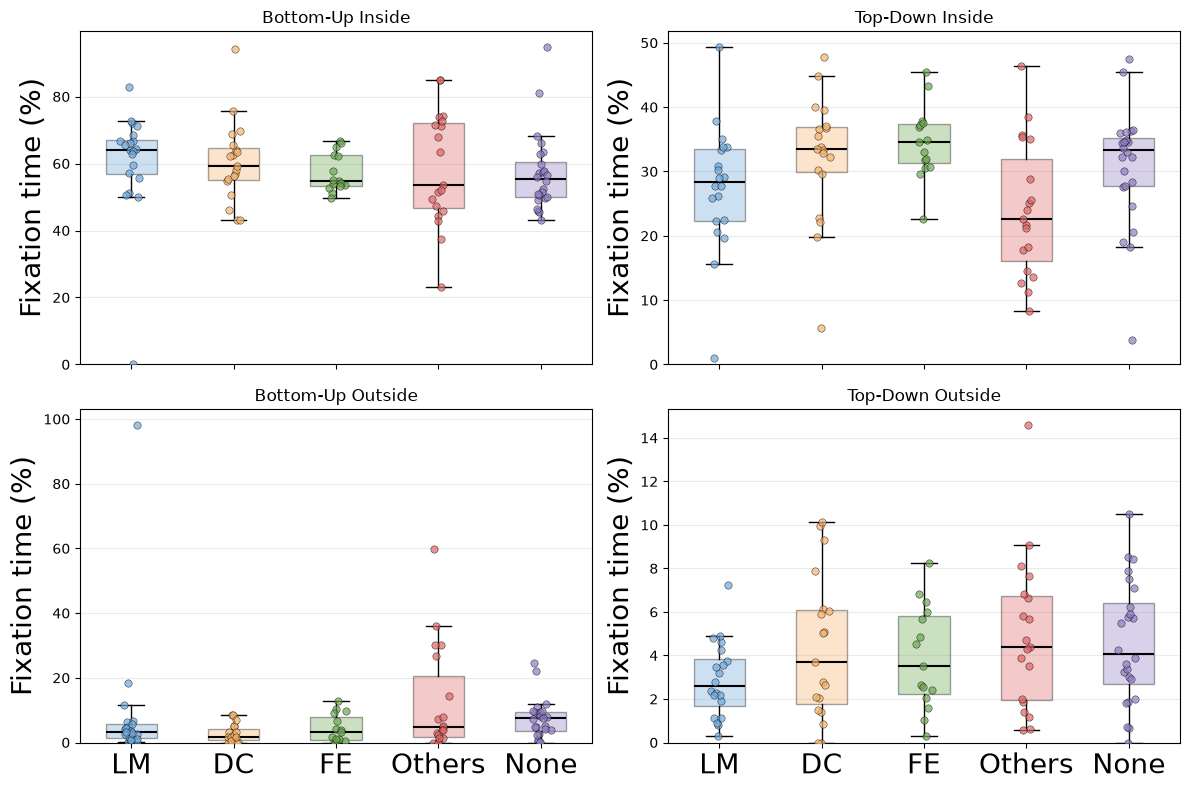

Saved to: /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq3/mental_model_states_by_perceived_smell.pdf


In [16]:
# ------------------------------------------------------------
# Boxplots — Mental-model states across perceived smell types
# Participant is the plotting unit
# ------------------------------------------------------------

MENTAL_MODEL_PLOT_METRICS = {
    "Bottom-Up Inside": "p_bu_inside",
    "Top-Down Inside": "p_td_inside",
    "Bottom-Up Outside": "p_bu_outside",
    "Top-Down Outside": "p_td_outside",
}

GROUP_ORDER = [
    "LM",
    "DC",
    "FE",
    "Others",
    "None",
]

GROUP_COLORS = {
    "LM": "#6FA8DC",
    "DC": "#F6B26B",
    "FE": "#6AA84F",
    "Others": "#E06666",
    "None": "#8E7CC3",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
    sharex=True,
)

axes = axes.flatten()

rng = np.random.default_rng(SEED)

for ax, (state_name, metric_col) in zip(
    axes,
    MENTAL_MODEL_PLOT_METRICS.items(),
):
    # One value per participant and perceived smell type.
    # This mirrors the participant-level aggregation used
    # in the inferential analysis.
    participant_table = (
        perceived_long[
            ["participant_id", "perceived_type", metric_col]
        ]
        .dropna(subset=[metric_col, "perceived_type"])
        .groupby(
            ["participant_id", "perceived_type"],
            as_index=False,
        )[metric_col]
        .mean()
    )

    data = [
        (
            participant_table.loc[
                participant_table["perceived_type"].eq(group),
                metric_col,
            ]
            .to_numpy()
            * 100
        )
        for group in GROUP_ORDER
    ]

    positions = np.arange(
        1,
        len(GROUP_ORDER) + 1,
    )

    positions = np.arange(
        1,
        len(GROUP_ORDER) + 1,
    )
    
    box = ax.boxplot(
        data,
        positions=positions,
        widths=0.50,
        showfliers=False,
        patch_artist=True,
        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.0,
        },
        capprops={
            "color": "black",
            "linewidth": 1.0,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.0,
        },
    )
    
    for patch, group in zip(
        box["boxes"],
        GROUP_ORDER,
    ):
        patch.set_facecolor(
            GROUP_COLORS[group]
        )
        patch.set_alpha(0.35)
    
    for position, values, group in zip(
        positions,
        data,
        GROUP_ORDER,
    ):
        jitter = rng.normal(
            loc=0,
            scale=0.04,
            size=len(values),
        )
    
        ax.scatter(
            position + jitter,
            values,
            s=28,
            alpha=0.70,
            color=GROUP_COLORS[group],
            edgecolor="black",
            linewidth=0.4,
            zorder=3,
        )

    ax.set_title(
        state_name,
        fontsize=12,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        GROUP_ORDER,
        fontsize=20,
    )

    ax.set_ylabel(
        "Fixation time (%)",
        fontsize=20,
    )

    ax.set_ylim(bottom=0)

    ax.grid(
        axis="y",
        alpha=0.25,
    )

    ax.set_axisbelow(True)


fig.tight_layout()

output_path = (
    OUTPUT_DIR
    / "mental_model_states_by_perceived_smell.pdf"
)

fig.savefig(
    output_path,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print("Saved to:", output_path.resolve())

---
## 7. Block B — Reading direction

Ten contrasts are evaluated for $P_{TTB}$ and treated as one FDR family.
\(\Delta>0\) indicates a larger proportion of Top-to-Bottom transitions in A.

In [17]:
DIRECTION_INDICATORS = {"P(Top-to-Bottom)": "p_top_to_bottom"}

display(describe_indicators(DIRECTION_INDICATORS))

direction_results = run_family("Reading direction", DIRECTION_INDICATORS)

table_b = format_results_table(direction_results)

display(table_b)

Group,LM,DC,FE,Others,None
Indicator,,,,,
P(Top-to-Bottom),"0.528 [0.512, 0.537]","0.520 [0.513, 0.535]","0.520 [0.503, 0.544]","0.525 [0.511, 0.547]","0.520 [0.512, 0.545]"


,Comparison,n,Δ (p.p.),95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,LM vs. DC,17,0.71,"[-0.89, 2.31]",0.3445,0.9591,0.71,"[0.47, 0.88]"
1,LM vs. FE,14,-0.07,"[-1.34, 1.21]",0.9089,0.9591,0.50,"[0.21, 0.79]"
2,DC vs. FE,13,-0.97,"[-3.27, 1.33]",0.3600,0.9591,0.31,"[0.08, 0.54]"
3,LM vs. None,20,0.09,"[-1.40, 1.59]",0.8947,0.9591,0.55,"[0.35, 0.75]"
4,DC vs. None,19,-0.79,"[-2.43, 0.85]",0.3153,0.9591,0.47,"[0.26, 0.68]"
5,FE vs. None,15,-0.29,"[-2.59, 2.00]",0.7760,0.9591,0.53,"[0.27, 0.80]"
6,LM vs. Others,15,0.22,"[-1.62, 2.06]",0.7897,0.9591,0.47,"[0.20, 0.73]"
7,DC vs. Others,14,-0.42,"[-1.95, 1.11]",0.5521,0.9591,0.36,"[0.14, 0.64]"
8,FE vs. Others,11,0.12,"[-2.51, 2.75]",0.9130,0.9591,0.55,"[0.27, 0.82]"
9,None vs. Others,19,-0.04,"[-1.55, 1.48]",0.9591,0.9591,0.42,"[0.21, 0.63]"


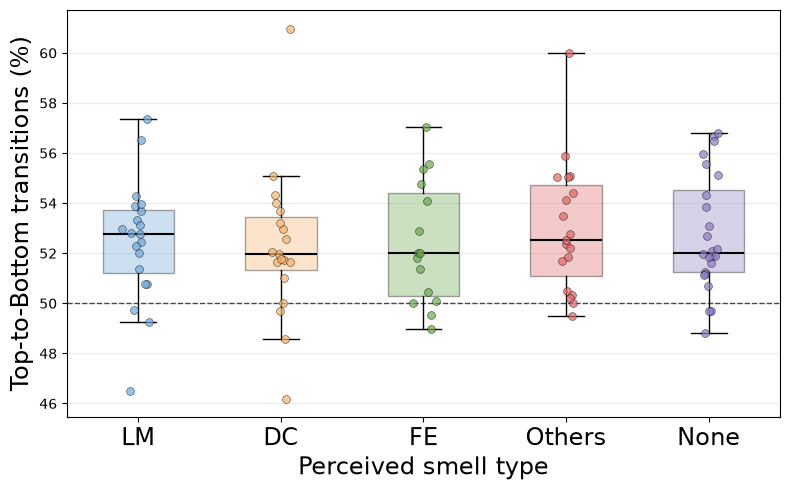

Saved to: /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq3/top_to_bottom_by_perceived_smell.pdf


In [18]:
# ------------------------------------------------------------
# Boxplot — Top-to-Bottom reading across perceived smell types
# Participant is the plotting unit
# ------------------------------------------------------------

GROUP_ORDER = [
    "LM",
    "DC",
    "FE",
    "Others",
    "None",
]

GROUP_COLORS = {
    "LM": "#6FA8DC",
    "DC": "#F6B26B",
    "FE": "#6AA84F",
    "Others": "#E06666",
    "None": "#8E7CC3",
}

participant_direction = (
    perceived_long[
        [
            "participant_id",
            "perceived_type",
            "p_top_to_bottom",
        ]
    ]
    .dropna(
        subset=[
            "perceived_type",
            "p_top_to_bottom",
        ]
    )
    .groupby(
        [
            "participant_id",
            "perceived_type",
        ],
        as_index=False,
    )["p_top_to_bottom"]
    .mean()
)

data = [
    (
        participant_direction.loc[
            participant_direction["perceived_type"].eq(group),
            "p_top_to_bottom",
        ]
        .to_numpy()
        * 100
    )
    for group in GROUP_ORDER
]

positions = np.arange(
    1,
    len(GROUP_ORDER) + 1,
)

fig, ax = plt.subplots(
    figsize=(8, 5),
)

box = ax.boxplot(
    data,
    positions=positions,
    widths=0.50,
    showfliers=False,
    patch_artist=True,
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
    whiskerprops={
        "color": "black",
        "linewidth": 1.0,
    },
    capprops={
        "color": "black",
        "linewidth": 1.0,
    },
    boxprops={
        "color": "black",
        "linewidth": 1.0,
    },
)

for patch, group in zip(
    box["boxes"],
    GROUP_ORDER,
):
    patch.set_facecolor(
        GROUP_COLORS[group]
    )
    patch.set_alpha(0.35)

rng = np.random.default_rng(SEED)

for position, values, group in zip(
    positions,
    data,
    GROUP_ORDER,
):
    jitter = rng.normal(
        loc=0,
        scale=0.04,
        size=len(values),
    )

    ax.scatter(
        position + jitter,
        values,
        s=32,
        alpha=0.70,
        color=GROUP_COLORS[group],
        edgecolor="black",
        linewidth=0.4,
        zorder=3,
    )

# Reference line: equal proportion of Top-to-Bottom and Bottom-to-Top
ax.axhline(
    y=50,
    color="black",
    linestyle="--",
    linewidth=1.0,
    alpha=0.7,
)

ax.set_xticks(positions)

ax.set_xticklabels(
    GROUP_ORDER,
    fontsize=17,
)

ax.set_ylabel(
    "Top-to-Bottom transitions (%)",
    fontsize=17,
)

ax.set_xlabel(
    "Perceived smell type",
    fontsize=17,
)


ax.grid(
    axis="y",
    alpha=0.25,
)

ax.set_axisbelow(True)

fig.tight_layout()

output_path = (
    OUTPUT_DIR
    / "top_to_bottom_by_perceived_smell.pdf"
)

fig.savefig(
    output_path,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print("Saved to:", output_path.resolve())

---
## 8. Block C — Reading depth

Ten contrasts are evaluated for $P_{Thorough}$ using the original 1000-ms threshold and treated as one FDR
family. \(\Delta>0\) indicates a larger proportion of fixations classified as Thorough in A and,
complementarily, a smaller proportion classified as Skimming.

In [19]:
DEPTH_INDICATORS = {"P(Thorough) @ 1000 ms": "p_thorough_1000"}

display(describe_indicators(DEPTH_INDICATORS))

depth_results = run_family("Reading depth", DEPTH_INDICATORS)

table_c = format_results_table(depth_results)

display(table_c)

Group,LM,DC,FE,Others,None
Indicator,,,,,
P(Thorough) @ 1000 ms,"0.093 [0.071, 0.110]","0.108 [0.083, 0.130]","0.115 [0.066, 0.138]","0.096 [0.080, 0.105]","0.090 [0.067, 0.131]"


,Comparison,n,Δ (p.p.),95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,LM vs. DC,17,-2.10,"[-3.14, -1.05]",0.0012,0.0117,0.06,"[0.00, 0.18]"
1,LM vs. FE,14,-2.12,"[-4.07, -0.16]",0.0369,0.1820,0.36,"[0.14, 0.64]"
2,DC vs. FE,13,0.49,"[-2.24, 3.21]",0.6919,0.8174,0.69,"[0.46, 0.92]"
3,LM vs. None,20,-0.65,"[-3.08, 1.79]",0.5699,0.8174,0.35,"[0.15, 0.55]"
4,DC vs. None,19,1.96,"[-0.05, 3.97]",0.0546,0.1820,0.68,"[0.47, 0.89]"
5,FE vs. None,15,0.59,"[-3.18, 4.36]",0.7282,0.8174,0.40,"[0.13, 0.67]"
6,LM vs. Others,15,-0.24,"[-1.83, 1.35]",0.7357,0.8174,0.40,"[0.13, 0.67]"
7,DC vs. Others,14,1.14,"[-1.03, 3.31]",0.2667,0.5333,0.57,"[0.29, 0.79]"
8,FE vs. Others,11,1.04,"[-0.98, 3.06]",0.2539,0.5333,0.55,"[0.27, 0.82]"
9,None vs. Others,19,-0.06,"[-2.20, 2.08]",0.9505,0.9505,0.42,"[0.21, 0.63]"


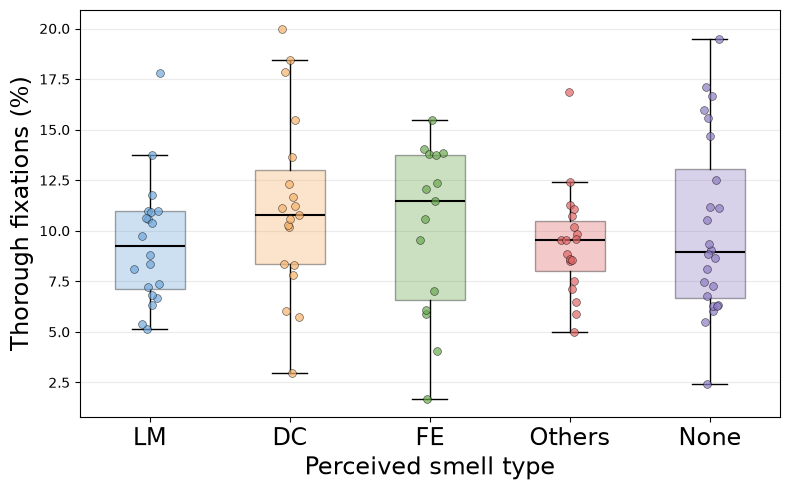

Saved to: /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq3/thorough_1000_by_perceived_smell.pdf


In [20]:
# ------------------------------------------------------------
# Boxplot — Thorough reading (1000 ms) across perceived smell types
# Participant is the plotting unit
# ------------------------------------------------------------

GROUP_ORDER = [
    "LM",
    "DC",
    "FE",
    "Others",
    "None",
]

GROUP_COLORS = {
    "LM": "#6FA8DC",
    "DC": "#F6B26B",
    "FE": "#6AA84F",
    "Others": "#E06666",
    "None": "#8E7CC3",
}

participant_thorough = (
    perceived_long[
        [
            "participant_id",
            "perceived_type",
            "p_thorough_1000",
        ]
    ]
    .dropna(
        subset=[
            "perceived_type",
            "p_thorough_1000",
        ]
    )
    .groupby(
        [
            "participant_id",
            "perceived_type",
        ],
        as_index=False,
    )["p_thorough_1000"]
    .mean()
)

data = [
    (
        participant_thorough.loc[
            participant_thorough["perceived_type"].eq(group),
            "p_thorough_1000",
        ]
        .to_numpy()
        * 100
    )
    for group in GROUP_ORDER
]

positions = np.arange(
    1,
    len(GROUP_ORDER) + 1,
)

fig, ax = plt.subplots(
    figsize=(8, 5),
)

box = ax.boxplot(
    data,
    positions=positions,
    widths=0.50,
    showfliers=False,
    patch_artist=True,
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
    whiskerprops={
        "color": "black",
        "linewidth": 1.0,
    },
    capprops={
        "color": "black",
        "linewidth": 1.0,
    },
    boxprops={
        "color": "black",
        "linewidth": 1.0,
    },
)

for patch, group in zip(
    box["boxes"],
    GROUP_ORDER,
):
    patch.set_facecolor(
        GROUP_COLORS[group]
    )
    patch.set_alpha(0.35)

rng = np.random.default_rng(SEED)

for position, values, group in zip(
    positions,
    data,
    GROUP_ORDER,
):
    jitter = rng.normal(
        loc=0,
        scale=0.04,
        size=len(values),
    )

    ax.scatter(
        position + jitter,
        values,
        s=32,
        alpha=0.70,
        color=GROUP_COLORS[group],
        edgecolor="black",
        linewidth=0.4,
        zorder=3,
    )

ax.set_xticks(positions)

ax.set_xticklabels(
    GROUP_ORDER,
    fontsize=17,
)

ax.set_ylabel(
    "Thorough fixations (%)",
    fontsize=17,
)

ax.set_xlabel(
    "Perceived smell type",
    fontsize=17,
)


ax.grid(
    axis="y",
    alpha=0.25,
)

ax.set_axisbelow(True)

fig.tight_layout()

output_path = (
    OUTPUT_DIR
    / "thorough_1000_by_perceived_smell.pdf"
)

fig.savefig(
    output_path,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print("Saved to:", output_path.resolve())

---
## 9. Block D — Reading organization

Ten contrasts are evaluated for $P_{Sectionally}$ using the primary **three-line moving-window**
operationalization, $|\Delta line|\le1$. These ten contrasts constitute one FDR family.

\(\Delta>0\) indicates a larger Sectionally proportion in A and, complementarily, a smaller Disorderly
proportion.

In [21]:
ORGANIZATION_INDICATORS = {"P(Sectionally) @ three-line moving window": "p_sectionally_within1"}

display(describe_indicators(ORGANIZATION_INDICATORS))

organization_results = run_family("Reading organization", ORGANIZATION_INDICATORS)

table_d = format_results_table(organization_results)

display(table_d)


Group,LM,DC,FE,Others,None
Indicator,,,,,
P(Sectionally) @ three-line moving window,"0.555 [0.474, 0.626]","0.452 [0.414, 0.513]","0.537 [0.502, 0.583]","0.525 [0.510, 0.608]","0.520 [0.493, 0.579]"


,Comparison,n,Δ (p.p.),95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,LM vs. DC,17,10.72,"[3.04, 18.40]",0.0111,0.0277,0.82,"[0.65, 1.00]"
1,LM vs. FE,14,1.78,"[-3.24, 6.80]",0.4438,0.5470,0.57,"[0.29, 0.79]"
2,DC vs. FE,13,-7.43,"[-12.28, -2.59]",0.0076,0.0255,0.15,"[0.00, 0.38]"
3,LM vs. None,20,2.83,"[-1.72, 7.38]",0.1983,0.3967,0.50,"[0.30, 0.70]"
4,DC vs. None,19,-7.93,"[-13.31, -2.54]",0.0076,0.0255,0.21,"[0.05, 0.42]"
5,FE vs. None,15,1.86,"[-3.16, 6.89]",0.4174,0.5470,0.53,"[0.27, 0.80]"
6,LM vs. Others,15,2.86,"[-6.31, 12.03]",0.4923,0.5470,0.53,"[0.27, 0.80]"
7,DC vs. Others,14,-8.63,"[-11.44, -5.83]",0.0001,0.0007,0.07,"[0.00, 0.21]"
8,FE vs. Others,11,1.01,"[-3.45, 5.46]",0.6003,0.6003,0.64,"[0.36, 0.91]"
9,None vs. Others,19,-1.59,"[-6.39, 3.20]",0.4829,0.5470,0.58,"[0.37, 0.79]"


---
## 10. Sensitivity analyses

Operational choices that may affect interpretation are evaluated through sensitivity analyses. Each
sensitivity analysis has **its own FDR family** and does not replace the corresponding primary analysis.

### 10.1 Skimming/Thorough threshold

The primary analysis retains the original 1000-ms threshold. Because fixation duration thresholds can
materially affect the Thorough/Skimming classification, we repeat the analysis with 300-, 500-, and
750-ms thresholds to assess the stability of the conclusions.

In [22]:
DEPTH_SENSITIVITY = {
    f"P(Thorough) @ {threshold} ms": f"p_thorough_{threshold}"
    for threshold in THOROUGH_THRESHOLDS
}

depth_sensitivity = run_family("Reading depth (sensitivity)", DEPTH_SENSITIVITY)

display(format_results_table(depth_sensitivity, with_indicator=True))

,Indicator,Comparison,n,Δ (p.p.),95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,P(Thorough) @ 300 ms,LM vs. DC,17,1.16,"[-2.01, 4.34]",0.4326,0.9505,0.53,"[0.29, 0.76]"
1,P(Thorough) @ 300 ms,LM vs. FE,14,-0.49,"[-4.98, 4.00]",0.8100,0.9505,0.64,"[0.36, 0.86]"
2,P(Thorough) @ 300 ms,DC vs. FE,13,-0.20,"[-6.17, 5.78]",0.9409,0.9505,0.46,"[0.23, 0.77]"
3,P(Thorough) @ 300 ms,LM vs. None,20,0.17,"[-2.40, 2.74]",0.8877,0.9505,0.60,"[0.40, 0.80]"
4,P(Thorough) @ 300 ms,DC vs. None,19,-1.27,"[-3.62, 1.09]",0.2636,0.8205,0.37,"[0.16, 0.58]"
5,P(Thorough) @ 300 ms,FE vs. None,15,-0.44,"[-5.87, 4.99]",0.8569,0.9505,0.40,"[0.13, 0.67]"
6,P(Thorough) @ 300 ms,LM vs. Others,15,1.05,"[-3.83, 5.93]",0.6325,0.9505,0.53,"[0.27, 0.80]"
7,P(Thorough) @ 300 ms,DC vs. Others,14,-1.51,"[-7.00, 3.98]",0.5495,0.9505,0.43,"[0.21, 0.71]"
8,P(Thorough) @ 300 ms,FE vs. Others,11,-1.10,"[-4.33, 2.14]",0.4387,0.9505,0.36,"[0.09, 0.64]"
9,P(Thorough) @ 300 ms,None vs. Others,19,1.19,"[-2.50, 4.88]",0.4960,0.9505,0.63,"[0.42, 0.84]"


### 10.2 Skimming/Thorough threshold — predominance

Section 10.1 only checks the between-category contrasts. The predominance conclusion ("Skimming
predominated", Section 5) also depends on the threshold, so the within-condition test against 0.50 is
repeated with 300-, 500-, 750- and 1000-ms thresholds, using the same procedure as Section 5 (20% trimmed
mean vs. 0.50 with Winsorized variance, and $\hat p_{pred}$ with a participant-level bootstrap CI).

Each threshold is its own Benjamini--Hochberg family: 2 tests for Smell/Clean and 5 tests for the perceived
types. The 1000-ms trimmed means are therefore identical to Section 5; only $p_{FDR}$ changes, because the
primary families also include the other three paired indicators.

In [23]:
PATTERN_DIRECTIONS.update(
    {
        f"P(Thorough) @ {threshold} ms": ("Thorough", "Skimming")
        for threshold in THOROUGH_THRESHOLDS
    }
)


def run_depth_predominance_sensitivity(
    data: pd.DataFrame,
    group_col: str,
    groups: list,
    family: str,
) -> pd.DataFrame:
    # One BH family per threshold, with the same tests as the primary predominance analysis.
    return pd.concat(
        [
            run_predominance(
                data=data,
                group_col=group_col,
                groups=groups,
                indicators={f"P(Thorough) @ {threshold} ms": f"p_thorough_{threshold}"},
                family=f"{family} @ {threshold} ms",
            ).assign(threshold=threshold)
            for threshold in THOROUGH_THRESHOLDS
        ],
        ignore_index=True,
    )


depth_predominance_smell_clean = run_depth_predominance_sensitivity(
    data=snippet_metrics,
    group_col="perceived_group",
    groups=PREDOMINANCE_SMELL_CLEAN_GROUPS,
    family="Predominance sensitivity — Smell/Clean",
)

depth_predominance_types = run_depth_predominance_sensitivity(
    data=perceived_long,
    group_col="perceived_type",
    groups=PREDOMINANCE_TYPE_GROUPS,
    family="Predominance sensitivity — perceived types",
)

depth_predominance_sensitivity = pd.concat(
    [depth_predominance_smell_clean, depth_predominance_types],
    ignore_index=True,
)

display(format_predominance_table(depth_predominance_sensitivity))

,Indicator,Condition,n,Trimmed mean,Δ vs. 0.50 (p.p.),95% CI Δ,p,p_FDR,p_pred,95% CI p_pred,n > 0.50,n < 0.50,n = 0.50,Predominance
0,P(Thorough) @ 300 ms,Smell,24,0.487,-1.32,"[-4.82, 2.18]",0.4326,0.5403,0.46,"[0.25, 0.67]",11,13,0,No clear predominance
1,P(Thorough) @ 300 ms,Clean,24,0.488,-1.16,"[-5.10, 2.78]",0.5403,0.5403,0.42,"[0.21, 0.62]",10,14,0,No clear predominance
2,P(Thorough) @ 500 ms,Smell,24,0.275,-22.53,"[-25.53, -19.53]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
3,P(Thorough) @ 500 ms,Clean,24,0.265,-23.48,"[-26.95, -20.01]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
4,P(Thorough) @ 750 ms,Smell,24,0.157,-34.26,"[-36.05, -32.46]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
5,P(Thorough) @ 750 ms,Clean,24,0.150,-35.00,"[-37.78, -32.21]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
6,P(Thorough) @ 1000 ms,Smell,24,0.100,-39.98,"[-41.20, -38.77]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
7,P(Thorough) @ 1000 ms,Clean,24,0.096,-40.38,"[-42.78, -37.99]",0.0000,0.0000,0.00,"[0.00, 0.00]",0,24,0,Skimming
8,P(Thorough) @ 300 ms,LM,20,0.496,-0.39,"[-3.48, 2.70]",0.7838,0.7838,0.50,"[0.30, 0.70]",10,10,0,No clear predominance
9,P(Thorough) @ 300 ms,DC,19,0.472,-2.77,"[-7.28, 1.73]",0.2049,0.7838,0.37,"[0.16, 0.58]",7,12,0,No clear predominance


In [24]:
# ------------------------------------------------------------
# LaTeX table — trimmed means of P(Thorough) by threshold
# ------------------------------------------------------------

PREDOMINANCE_MARK = {"Skimming": "S", "Thorough": "T"}


def threshold_header(threshold: int) -> str:
    return f"{threshold:,} ms"


def predominance_cell(row) -> str:
    mark = PREDOMINANCE_MARK.get(row["predominance"])
    superscript = f"$^{{{mark}}}$" if mark else r"\textsuperscript{--}"
    return f"{row['trimmed_mean']:.3f}{superscript}"


def threshold_sensitivity_latex(
    results: pd.DataFrame,
    groups: list,
    row_label: str,
    caption_scope: str,
    label: str,
) -> str:
    cells = (
        results.loc[results["status"].eq("ok")]
        .assign(cell=lambda frame: frame.apply(predominance_cell, axis=1))
        .pivot(index="condition", columns="threshold", values="cell")
        .reindex(index=groups, columns=THOROUGH_THRESHOLDS)
        .fillna("n/a")
    )

    width = max(len(row_label), *(len(group) for group in groups))
    header = " & ".join([row_label] + [threshold_header(t) for t in THOROUGH_THRESHOLDS])
    body = "\n".join(
        f"{group:<{width}} & " + " & ".join(cells.loc[group]) + r" \\"
        for group in groups
    )

    return (
        "\\begin{table}[ht]\n"
        "\\centering\n"
        "\\caption{Sensitivity of the Thorough/Skimming predominance analysis to the\n"
        f"fixation-duration threshold ({caption_scope}). Values are participant-level 20\\% trimmed\n"
        "means of $P_{Thorough}$; superscripts indicate the predominant pattern\n"
        "after Benjamini--Hochberg correction within each threshold\n"
        "(S = Skimming, T = Thorough, -- = unclear).}\n"
        f"\\label{{{label}}}\n"
        "\\begin{tabular}{l" + "c" * len(THOROUGH_THRESHOLDS) + "}\n"
        "\\toprule\n"
        f"{header} \\\\\n"
        "\\midrule\n"
        f"{body}\n"
        "\\bottomrule\n"
        "\\end{tabular}\n"
        "\\end{table}\n"
    )


THRESHOLD_SENSITIVITY_TEX = {
    "rq3_table_thorough_threshold_sensitivity_types.tex": threshold_sensitivity_latex(
        depth_predominance_types,
        groups=PREDOMINANCE_TYPE_GROUPS,
        row_label="Type",
        caption_scope="perceived code-smell types",
        label="tab:thorough_threshold_sensitivity",
    ),
    "rq3_table_thorough_threshold_sensitivity_smell_clean.tex": threshold_sensitivity_latex(
        depth_predominance_smell_clean,
        groups=PREDOMINANCE_SMELL_CLEAN_GROUPS,
        row_label="Condition",
        caption_scope="Smell vs. Clean",
        label="tab:thorough_threshold_sensitivity_smell_clean",
    ),
}

for filename, tex in THRESHOLD_SENSITIVITY_TEX.items():
    (OUTPUT_DIR / filename).write_text(tex, encoding="utf-8")
    print(f"Saved: {filename}\n")
    print(tex)

Saved: rq3_table_thorough_threshold_sensitivity_types.tex

\begin{table}[ht]
\centering
\caption{Sensitivity of the Thorough/Skimming predominance analysis to the
fixation-duration threshold (perceived code-smell types). Values are participant-level 20\% trimmed
means of $P_{Thorough}$; superscripts indicate the predominant pattern
after Benjamini--Hochberg correction within each threshold
(S = Skimming, T = Thorough, -- = unclear).}
\label{tab:thorough_threshold_sensitivity}
\begin{tabular}{lcccc}
\toprule
Type & 300 ms & 500 ms & 750 ms & 1,000 ms \\
\midrule
LM     & 0.496\textsuperscript{--} & 0.270$^{S}$ & 0.147$^{S}$ & 0.092$^{S}$ \\
DC     & 0.472\textsuperscript{--} & 0.279$^{S}$ & 0.166$^{S}$ & 0.109$^{S}$ \\
FE     & 0.488\textsuperscript{--} & 0.280$^{S}$ & 0.167$^{S}$ & 0.107$^{S}$ \\
Others & 0.480\textsuperscript{--} & 0.262$^{S}$ & 0.145$^{S}$ & 0.092$^{S}$ \\
None   & 0.488\textsuperscript{--} & 0.265$^{S}$ & 0.150$^{S}$ & 0.096$^{S}$ \\
\bottomrule
\end{tabular}
\end{t

### 10.3 Sectionally definition

The primary definition uses a **three-line moving window** centered on the currently fixated line:

$$|\Delta line|\le1.$$

To assess whether the findings depend on this operationalization, we repeat the analysis using:

- fixed three-line blocks (`1–3`, `4–6`, `7–9`, ...);
- $|\Delta line|\le2$;
- $|\Delta line|\le3$;
- $|\Delta line|\le5$.

The moving-window definition avoids the boundary artifact of fixed blocks, under which an adjacent-line
transition such as `3 → 4` would be classified as a section change.

In [25]:
ORGANIZATION_SENSITIVITY = {
    "Primary: P(Sectionally) @ |Δ line| ≤ 1": "p_sectionally_within1",
    "Sensitivity: fixed 3-line blocks": "p_sectionally_blocks3",
    "Sensitivity: P(Sectionally) @ |Δ line| ≤ 2": "p_sectionally_within2",
    "Sensitivity: P(Sectionally) @ |Δ line| ≤ 3": "p_sectionally_within3",
    "Sensitivity: P(Sectionally) @ |Δ line| ≤ 5": "p_sectionally_within5",
}

organization_sensitivity = run_family(
    "Reading organization (sensitivity)", ORGANIZATION_SENSITIVITY
)

display(format_results_table(organization_sensitivity, with_indicator=True))


,Indicator,Comparison,n,Δ (p.p.),95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,Primary: P(Sectionally) @ |Δ line| ≤ 1,LM vs. DC,17,10.72,"[3.04, 18.40]",0.0111,0.0461,0.82,"[0.65, 1.00]"
1,Primary: P(Sectionally) @ |Δ line| ≤ 1,LM vs. FE,14,1.78,"[-3.24, 6.80]",0.4438,0.6164,0.57,"[0.29, 0.79]"
2,Primary: P(Sectionally) @ |Δ line| ≤ 1,DC vs. FE,13,-7.43,"[-12.28, -2.59]",0.0076,0.0461,0.15,"[0.00, 0.38]"
3,Primary: P(Sectionally) @ |Δ line| ≤ 1,LM vs. None,20,2.83,"[-1.72, 7.38]",0.1983,0.3814,0.50,"[0.30, 0.70]"
4,Primary: P(Sectionally) @ |Δ line| ≤ 1,DC vs. None,19,-7.93,"[-13.31, -2.54]",0.0076,0.0461,0.21,"[0.05, 0.42]"
5,Primary: P(Sectionally) @ |Δ line| ≤ 1,FE vs. None,15,1.86,"[-3.16, 6.89]",0.4174,0.5963,0.53,"[0.27, 0.80]"
6,Primary: P(Sectionally) @ |Δ line| ≤ 1,LM vs. Others,15,2.86,"[-6.31, 12.03]",0.4923,0.6311,0.53,"[0.27, 0.80]"
7,Primary: P(Sectionally) @ |Δ line| ≤ 1,DC vs. Others,14,-8.63,"[-11.44, -5.83]",0.0001,0.0033,0.07,"[0.00, 0.21]"
8,Primary: P(Sectionally) @ |Δ line| ≤ 1,FE vs. Others,11,1.01,"[-3.45, 5.46]",0.6003,0.7147,0.64,"[0.36, 0.91]"
9,Primary: P(Sectionally) @ |Δ line| ≤ 1,None vs. Others,19,-1.59,"[-6.39, 3.20]",0.4829,0.6311,0.58,"[0.37, 0.79]"


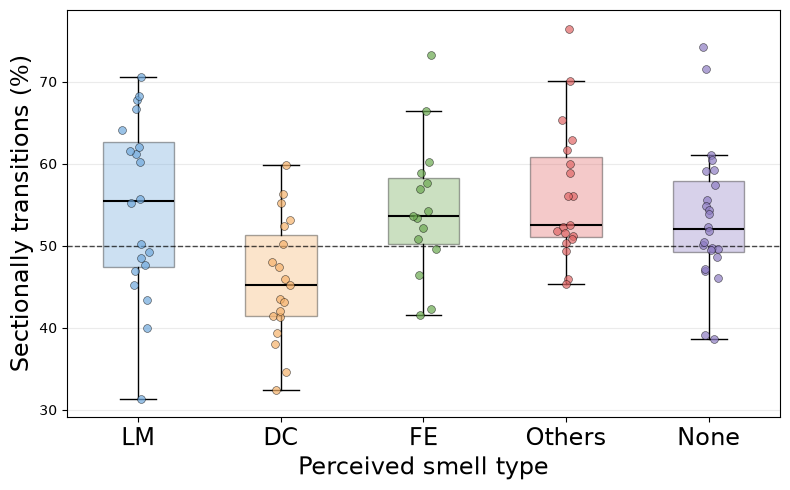

Saved to: /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq3/sectionally_by_perceived_smell.pdf


In [26]:
# ------------------------------------------------------------
# Boxplot — Sectionally reading across perceived smell types
# Primary three-line moving-window operationalization
# Participant is the plotting unit
# ------------------------------------------------------------

GROUP_ORDER = [
    "LM",
    "DC",
    "FE",
    "Others",
    "None",
]

GROUP_COLORS = {
    "LM": "#6FA8DC",
    "DC": "#F6B26B",
    "FE": "#6AA84F",
    "Others": "#E06666",
    "None": "#8E7CC3",
}

participant_sectionally = (
    perceived_long[
        [
            "participant_id",
            "perceived_type",
            "p_sectionally_within1",
        ]
    ]
    .dropna(
        subset=[
            "perceived_type",
            "p_sectionally_within1",
        ]
    )
    .groupby(
        [
            "participant_id",
            "perceived_type",
        ],
        as_index=False,
    )["p_sectionally_within1"]
    .mean()
)

data = [
    (
        participant_sectionally.loc[
            participant_sectionally["perceived_type"].eq(group),
            "p_sectionally_within1",
        ]
        .to_numpy()
        * 100
    )
    for group in GROUP_ORDER
]

positions = np.arange(
    1,
    len(GROUP_ORDER) + 1,
)

fig, ax = plt.subplots(
    figsize=(8, 5),
)

box = ax.boxplot(
    data,
    positions=positions,
    widths=0.50,
    showfliers=False,
    patch_artist=True,
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
    whiskerprops={
        "color": "black",
        "linewidth": 1.0,
    },
    capprops={
        "color": "black",
        "linewidth": 1.0,
    },
    boxprops={
        "color": "black",
        "linewidth": 1.0,
    },
)

for patch, group in zip(
    box["boxes"],
    GROUP_ORDER,
):
    patch.set_facecolor(
        GROUP_COLORS[group]
    )
    patch.set_alpha(0.35)

rng = np.random.default_rng(SEED)

for position, values, group in zip(
    positions,
    data,
    GROUP_ORDER,
):
    jitter = rng.normal(
        loc=0,
        scale=0.04,
        size=len(values),
    )

    ax.scatter(
        position + jitter,
        values,
        s=32,
        alpha=0.70,
        color=GROUP_COLORS[group],
        edgecolor="black",
        linewidth=0.4,
        zorder=3,
    )

# Equal Sectionally / Disorderly reference
ax.axhline(
    y=50,
    color="black",
    linestyle="--",
    linewidth=1.0,
    alpha=0.7,
)

ax.set_xticks(positions)

ax.set_xticklabels(
    GROUP_ORDER,
    fontsize=17,
)

ax.set_ylabel(
    "Sectionally transitions (%)",
    fontsize=17,
)

ax.set_xlabel(
    "Perceived smell type",
    fontsize=17,
)


ax.grid(
    axis="y",
    alpha=0.25,
)

ax.set_axisbelow(True)

fig.tight_layout()

output_path = (
    OUTPUT_DIR
    / "sectionally_by_perceived_smell.pdf"
)

fig.savefig(
    output_path,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print("Saved to:", output_path.resolve())

---
## 11. Summary of results surviving FDR correction

**Between-condition/category comparisons** and **within-condition predominance analyses** answer different
questions and use separate FDR families.

- `Smell vs. Clean` and the type-specific contrasts test **differences between conditions/categories**.
- Predominance analyses test whether the trimmed mean of a proportion differs from 0.50 **within a given
  condition/category**.

The lists below are only an index of results with \(p_{FDR}<0.05\) within the corresponding family. Contrast
interpretation should also consider \(\Delta\), the 95% CI, and \(\hat p\). Predominance interpretation should
also consider the trimmed mean, its direction relative to 0.50, and \(\hat p_{pred}\).

In [27]:
type_results = pd.concat(
    [
        mental_results,
        direction_results,
        depth_results,
        organization_results,
    ],
    ignore_index=True,
)

all_main_results = pd.concat(
    [
        smell_clean_results,
        type_results,
    ],
    ignore_index=True,
)

significant = (
    all_main_results.loc[
        all_main_results["p_fdr"].lt(ALPHA)
    ]
    .sort_values(["family", "p_fdr"])
)

print("=== Between-condition/category differences ===")
print(f"Smell vs. Clean contrasts         : {len(smell_clean_results)}")
print(f"Type-specific contrasts           : {len(type_results)}")
print(f"Total primary contrasts           : {len(all_main_results)}")
print(f"Contrasts with p_FDR < {ALPHA}       : {len(significant)}")
print()

if significant.empty:
    print("  none")

for _, row in significant.iterrows():
    print(
        f"  {row['family']:<28}"
        f"{row['indicator']:<38}"
        f"{row['comparison']:<17}"
        f"Δ = {row['delta_pp']:>7,.2f} p.p."
        f"   IC {format_interval(row['ci_low_pp'], row['ci_high_pp']):<20}"
        f"p_FDR = {row['p_fdr']:.4f}   p-hat = {row['phat']:.2f}"
    )


predominance_main_results = pd.concat(
    [
        predominance_smell_clean_results,
        predominance_type_results,
    ],
    ignore_index=True,
)

significant_predominance = (
    predominance_main_results.loc[
        predominance_main_results["p_fdr"].lt(ALPHA)
    ]
    .sort_values(["family", "indicator", "p_fdr"])
)

print()
print("=== Predominance within conditions/categories ===")
print(
    "Smell/Clean tests vs. 0.50       :",
    len(predominance_smell_clean_results),
)
print(
    "Perceived-type tests vs. 0.50    :",
    len(predominance_type_results),
)
print(
    "Total predominance tests          :",
    len(predominance_main_results),
)
print(
    f"Predominance tests with p_FDR < {ALPHA}  :",
    len(significant_predominance),
)
print()

if significant_predominance.empty:
    print("  none")

for _, row in significant_predominance.iterrows():
    print(
        f"  {row['condition']:<8}"
        f"{row['indicator']:<38}"
        f"trimmed mean = {row['trimmed_mean']:.3f}   "
        f"Δ0.50 = {row['delta_pp']:>7,.2f} p.p.   "
        f"p_FDR = {row['p_fdr']:.4f}   "
        f"p_pred = {row['p_pred']:.2f}   "
        f"→ {row['predominance']}"
    )

=== Between-condition/category differences ===
Smell vs. Clean contrasts         : 7
Type-specific contrasts           : 70
Total primary contrasts           : 77
Contrasts with p_FDR < 0.05       : 6

  Mental model — P(Bottom-Up Inside)P(Bottom-Up Inside)                   LM vs. None      Δ =    8.14 p.p.   IC [3.66, 12.62]       p_FDR = 0.0208   p-hat = 0.75
  Reading depth               P(Thorough) @ 1000 ms                 LM vs. DC        Δ =   -2.10 p.p.   IC [-3.14, -1.05]      p_FDR = 0.0117   p-hat = 0.06
  Reading organization        P(Sectionally) @ three-line moving windowDC vs. Others    Δ =   -8.63 p.p.   IC [-11.44, -5.83]     p_FDR = 0.0007   p-hat = 0.07
  Reading organization        P(Sectionally) @ three-line moving windowDC vs. FE        Δ =   -7.43 p.p.   IC [-12.28, -2.59]     p_FDR = 0.0255   p-hat = 0.15
  Reading organization        P(Sectionally) @ three-line moving windowDC vs. None      Δ =   -7.93 p.p.   IC [-13.31, -2.54]     p_FDR = 0.0255   p-hat = 0.2

In [28]:
sensitivity_results = pd.concat(
    [
        depth_sensitivity,
        organization_sensitivity,
    ],
    ignore_index=True,
)

robustness = (
    sensitivity_results.loc[
        sensitivity_results["p_fdr"].lt(ALPHA)
    ]
    .groupby(["family", "comparison"])["indicator"]
    .apply(list)
)

print("Contrasts with p_FDR < 0.05 nas análises de sensibilidade:")
print()

if robustness.empty:
    print("  none")

for (family, comparison), indicators in robustness.items():
    print(
        f"  {family:<40} "
        f"{comparison:<16} "
        f"{indicators}"
    )

Contrasts with p_FDR < 0.05 nas análises de sensibilidade:

  Reading depth (sensitivity)              LM vs. DC        ['P(Thorough) @ 750 ms', 'P(Thorough) @ 1000 ms']
  Reading organization (sensitivity)       DC vs. FE        ['Primary: P(Sectionally) @ |Δ line| ≤ 1']
  Reading organization (sensitivity)       DC vs. None      ['Primary: P(Sectionally) @ |Δ line| ≤ 1', 'Sensitivity: fixed 3-line blocks', 'Sensitivity: P(Sectionally) @ |Δ line| ≤ 2', 'Sensitivity: P(Sectionally) @ |Δ line| ≤ 3']
  Reading organization (sensitivity)       DC vs. Others    ['Primary: P(Sectionally) @ |Δ line| ≤ 1', 'Sensitivity: P(Sectionally) @ |Δ line| ≤ 2', 'Sensitivity: P(Sectionally) @ |Δ line| ≤ 3']
  Reading organization (sensitivity)       LM vs. DC        ['Primary: P(Sectionally) @ |Δ line| ≤ 1', 'Sensitivity: fixed 3-line blocks', 'Sensitivity: P(Sectionally) @ |Δ line| ≤ 2', 'Sensitivity: P(Sectionally) @ |Δ line| ≤ 3']


---
## 12. Export results

In [29]:
EXPORTS = {
    "rq3_snippet_metrics.csv": snippet_metrics,
    "rq3_smell_clean_descriptive.csv": smell_clean_descriptive.reset_index(),
    "rq3_smell_clean_results.csv": smell_clean_results,
    "rq3_table_smell_clean.csv": table_smell_clean,
    "rq3_predominance_smell_clean_results.csv": predominance_smell_clean_results,
    "rq3_table_predominance_smell_clean.csv": table_predominance_smell_clean,
    "rq3_predominance_types_results.csv": predominance_type_results,
    "rq3_table_predominance_types.csv": table_predominance_types,
    "rq3_all_predominance_results.csv": predominance_main_results,
    "rq3_tableA_mental_model_state_contrasts.csv": table_a,
    "rq3_tableB_reading_direction.csv": table_b,
    "rq3_tableC_reading_depth.csv": table_c,
    "rq3_tableD_reading_organization.csv": table_d,
    "rq3_mental_model_four_state_composition.csv": composition.reset_index(),
    "rq3_specific_type_results.csv": type_results,
    "rq3_all_main_results.csv": all_main_results,
    "rq3_sensitivity_results.csv": sensitivity_results,
    "rq3_predominance_threshold_sensitivity.csv": depth_predominance_sensitivity,
}

for filename, frame in EXPORTS.items():
    frame.to_csv(
        OUTPUT_DIR / filename,
        index=False,
    )
    print(
        "Saved:",
        (OUTPUT_DIR / filename).name,
    )

Saved: rq3_snippet_metrics.csv
Saved: rq3_smell_clean_descriptive.csv
Saved: rq3_smell_clean_results.csv
Saved: rq3_table_smell_clean.csv
Saved: rq3_predominance_smell_clean_results.csv
Saved: rq3_table_predominance_smell_clean.csv
Saved: rq3_predominance_types_results.csv
Saved: rq3_table_predominance_types.csv
Saved: rq3_all_predominance_results.csv
Saved: rq3_tableA_mental_model_state_contrasts.csv
Saved: rq3_tableB_reading_direction.csv
Saved: rq3_tableC_reading_depth.csv
Saved: rq3_tableD_reading_organization.csv
Saved: rq3_mental_model_four_state_composition.csv
Saved: rq3_specific_type_results.csv
Saved: rq3_all_main_results.csv
Saved: rq3_sensitivity_results.csv
Saved: rq3_predominance_threshold_sensitivity.csv


---
## Interpretation limitations

The `Smell vs. Clean` comparison uses the **participant's perception**, rather than an experimental
manipulation that randomizes smell presence. In addition, different snippets contribute to the two conditions.
Observed differences therefore describe sets of snippets perceived as containing or not containing smells;
they do not establish that smell presence caused the observed reading behavior.

The same caution applies to type-specific contrasts. Snippet identity remains confounded with structural
properties of the code.

The four mental-model states reproduce the gaze-based operational framework of Bottom-Up/Top-Down crossed
with Inside/Outside. These labels are behavioral proxies derived from fixation transitions and location; they
should not be interpreted as direct observations of developers' internal cognitive models.

The four state shares form a composition and sum to 1. Consequently, an increase in one state necessarily
corresponds to a decrease in one or more of the remaining states. Individual state contrasts should therefore
be interpreted jointly with the descriptive four-state composition.

Predominance analyses answer a different question. For the mental-model dimension, the predominance test
uses the marginal proportion

\[
P_{BU}=P_{BU,I}+P_{BU,O}
\]

and compares it with 0.50. Finding Bottom-Up predominance within a condition does not show that a smell
induced Bottom-Up behavior. Evidence of an association with smell condition comes from the direct
between-condition contrasts.

Results should therefore be reported as observed differences or associations, not as causal claims or direct
measurements of cognitive processes.